# Experiment 1 replication & risk preference


## Cohort and risk-score settings

`MATCH_R_RISK_CE_COHORT = True` retains the uploaded notebook's strict cohort:
complete maze/session, 60-second deadline, the full31 psm_usd450 protocol, and a monotonic risk switching point. 

CE is the **raw dollar midpoint** between the highest sure amount rejected and
the lowest accepted amount. No centering, normalization, or logit is applied.
Higher CE means greater willingness to choose the lottery in this questionnaire.

In [3]:
from pathlib import Path
from decimal import Decimal, ROUND_HALF_UP
import json, ast, warnings, pickle, os, math, random, heapq, itertools
from collections import Counter, deque
from copy import deepcopy
import numpy as np
import pandas as pd
import scipy
from scipy import stats
from scipy.stats import ttest_rel, wilcoxon
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib import gridspec
import matplotlib.patches as patches
from matplotlib.collections import PolyCollection
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
try:
    from IPython.display import display
except ImportError:  # also permits running extracted code as a plain Python script
    display = print

# Run from the directory containing this notebook.
# Place ONLY individual raw jsPsych CSVs in this folder.
BASE_DIR = Path('../experiment')
RAW_DATA_DIR = BASE_DIR / 'data/exp1_survey/raw'
OUTPUT_DIR = Path('data/exp1_survey')
FIGURE_DIR = Path('fig/exp1_survey')
MODEL_DIR = Path('modelfits/exp1_survey')
for folder in (OUTPUT_DIR, FIGURE_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)
figpath, fitspath, data_savepath = map(str, (FIGURE_DIR, MODEL_DIR, OUTPUT_DIR))

EXPECTED_MAZE_TRIALS = 30
EXPECTED_DEADLINE_MS = 60000
# Original actual exclusion calculation (including its max-over-conditions rule).
APPLY_ORIGINAL_EXCLUSIONS = True
MANUAL_EXCLUDE_IDS = set()  # e.g. {'PARTICIPANT_ID'} when production data are added
# No maze-specific timeout rejection threshold was specified. Set e.g. 0.5
# only after choosing that rule; comparison is strictly greater than threshold.
MAZE_TIMEOUT_REVIEW_THRESHOLD = None
RUN_ORIGINAL_ANALYSES = True
start_goal_pos = [(8, 1), (8, 15)]
maze_size = 17

# Exclude participants whose maze strategy or maze summary contains the white-text trick word "tiramisu" (case-insensitive).
EXCLUDE_TIRAMISU_STRATEGY = True
# Preserve the uploaded notebook's risk-cohort switch.
MATCH_R_RISK_CE_COHORT = False
R_RISK_MODE = "full31"
R_RISK_PRESET = "psm_usd450"



## Original maze helper functions (mixed-model helpers removed)

In [4]:
def maze_to_char_array(maze):
    return np.array([list(row) for row in maze])

def grid_to_rowstrings(s: str):
    grid = json.loads(s)          # -> list[list[str]]
    return [''.join(row) for row in grid]


def solve_maze_BestFirstSearch(maze, start=None, end=None, heuristic="Manhattan"):
    """
    Perform greedy best-first search on a rectangular maze.

    Parameters
    ----------
    maze : List[str]
        Maze represented as a list of strings of equal length.
        maze[row][col] == '#' for walls, '.' for free space.
    start : (col, row)
        Tuple giving the starting cell coordinates.
    end : (col, row)
        Tuple giving the end cell coordinates.
    heuristic: "Manhattan" or "Euclidean"
        Heuristic value function used to guide which square to evaluate next. 

    Returns
    -------
    path : List[(col, row)]
        The sequence of cells from start to end (inclusive), or [] if none found.
    evaluated : List[(col, row)]
        The cells popped from the priority queue, in order of expansion.
    walls : List[(col, row)]
        All wall‐cells that were examined as neighbors during the search.
    """
    width  = len(maze[0])
    height = len(maze)
    
    if(start is None):
        for x in range(width):
            if maze[0][x] == '.':
                start = (x, 0)
                break
        for x in range(width):
            if maze[height-1][x] == '.':
                end = (x, height-1)
                break

    def h(cell, distance="Manhattan"):
        c, r = cell
        gc, gr = end
        if(distance=="Manhattan"):
            return abs(c - gc) + abs(r - gr)
        elif(distance=="Euclidean"):
            return np.sqrt((c - gc)**2 + (r - gr)**2)

    # Min-heap of (priority, (col, row))
    frontier = [(h(start, distance=heuristic), start)]
    came_from = {start: None}
    visited   = {start}
    evaluated  = []
    walls      = []

    while frontier:
        _, current = heapq.heappop(frontier)
        evaluated.append(current)

        if current == end:
            break

        c, r = current
        for dc, dr in [(0,-1), (0,1), (-1,0), (1,0)]:
            nc, nr = c + dc, r + dr
            if not (0 <= nc < width and 0 <= nr < height):
                continue

            neighbor = (nc, nr)
            if neighbor in visited:
                continue

            if maze[nr][nc] == '#':
                walls.append(neighbor)
                continue

            visited.add(neighbor)
            came_from[neighbor] = current
            heapq.heappush(frontier, (h(neighbor, distance=heuristic), neighbor))

    # Reconstruct path
    path = []
    if end in came_from:
        node = end
        while node is not None:
            path.append(node)
            node = came_from[node]
        path.reverse()

    return path, evaluated, walls   
    

def visualize_maze_colored(maze,
                           num_colors,
                           figsize=None,
                           start_goal_pos = None,
                           start_goal=False,
                           path=None,
                           legend=False,
                           palette_name='tab20',
                           adj_sq_notsamecolor = True,
                           plt_show=True):
    """
    Visualize a maze with randomly assigned colors; but ensure no two
    adjacent cells of the same type share a color (greedy coloring).
    Parameters:
      - maze: list of strings ('#' walls, other symbols are all passages)
      - num_colors: total number of colors (must be >=2 and even)
      - figsize: tuple for figure size
      - start_goal: if True mark only start/end, else draw full path
      - path: list of (x,y) coordinates to overlay
      - legend: whether to draw the maze+legend (True) or just the maze (False)
      - palette_name: Matplotlib colormap name, e.g. 'tab20' or 'gray'
      - adj_sq_notsamecolor: if True, ensure no two adjacent cells of the same type share a color.
      - plt_show: if True, calls plt.show(); else leaves the figure open for saving downstream
    """
    # Randomize colors for each trial
    cmap = plt.get_cmap(palette_name)
    
    if(palette_name != "gray"):
        colors = [cmap(i) for i in range(20)]
        random.shuffle(colors)
        # 2. Split into wall-colors and passage-colors
        half = num_colors // 2
        wall_colors = colors[:half]
        passage_colors = colors[half:num_colors]
    else: # Black and white maze
#         positions = np.linspace(0, 1, num_colors)
        positions = np.linspace(0.85,1, num_colors)
        colors = [cmap(pos) for pos in positions]
        # 2. Split into wall-colors and passage-colors
        half = num_colors // 2
        wall_colors = colors[0:half]
        passage_colors = colors[-half:]

    H, W = len(maze), len(maze[0])
    # 2) Greedy coloring: no same‐type neighbors share a color
    img = np.zeros((H, W, 3), dtype=float)
    
    if(adj_sq_notsamecolor): # Ensure that no adjacent squares share the same color. Works only with num_colors>=8, due to the four-color theorem.
        assigned = [[None]*W for _ in range(H)]
        for y in range(H):
            for x in range(W):
                palette = wall_colors if maze[y][x] == '#' else passage_colors
                # collect forbidden from up and left if same type
                forbidden = set()
                for dy, dx in [(-1,0),(0,-1)]:
                    ny, nx = y+dy, x+dx
                    if 0 <= ny < H and 0 <= nx < W and maze[ny][nx] == maze[y][x]:
                        c = assigned[ny][nx]
                        if c is not None:
                            forbidden.add(c)
                # choose from palette avoiding forbidden
                choices = [c for c in palette if c not in forbidden]
                chosen = random.choice(choices) if choices else random.choice(palette)
                assigned[y][x] = chosen
                img[y, x] = chosen[:3]
    else:
        for y in range(H):
            for x in range(W):
                if maze[y][x] == '#':
                    color = random.choice(wall_colors)
                else:
                    color = random.choice(passage_colors)
                img[y, x] = color[:3]  # drop alpha channel

    # 3) Display
    if not legend:
        if figsize is None:
            plt.figure(figsize=(W/5, H/5))
        else:
            plt.figure(figsize=figsize)
        plt.imshow(img, interpolation='nearest')
        plt.xticks([]); plt.yticks([])
        if path:
            xs, ys = zip(*path)
            if(start_goal_pos is None):
                ax_maze.plot(xs[0], ys[0], '.', color='red', markersize=20)
                ax_maze.plot(xs[-1], ys[-1], '*', color='red', markersize=12)
            else:
                ax_maze.plot(start_goal_pos[0][0], start_goal_pos[0][1], '.', color='red', markersize=20)
                ax_maze.plot(start_goal_pos[1][0], start_goal_pos[1][1], '*', color='red', markersize=12)
            if not start_goal:
                plt.plot(xs, ys, color='red', linewidth=2)
        if plt_show:
            plt.show()
    else:
        # maze+legend side by side
        if figsize is None:
            figsize = ((W + half)/5, H/5)
        fig, (ax_maze, ax_leg) = plt.subplots(
            1, 2,
            figsize=figsize,
            gridspec_kw={'width_ratios': [W, max(8, num_colors)//2 * 1.2],
                         'wspace': 0.25}
        )
        # draw maze
        ax_maze.imshow(img, interpolation='nearest')
        ax_maze.set_xticks([]); ax_maze.set_yticks([])
        ax_maze.set_aspect('equal')
        if path:
            xs, ys = zip(*path)
            if(start_goal_pos is None):
                ax_maze.plot(xs[0], ys[0], '.', color='red', markersize=20)
                ax_maze.plot(xs[-1], ys[-1], '*', color='red', markersize=12)
            else:
                ax_maze.plot(start_goal_pos[0][0], start_goal_pos[0][1], '.', color='red', markersize=20)
                ax_maze.plot(start_goal_pos[1][0], start_goal_pos[1][1], '*', color='red', markersize=12)
            if not start_goal: # Visualize only start and end points of the maze, not path
                ax_maze.plot(xs, ys, color='red', linewidth=2)

        # draw legend
        legend_size = 1.5
        ax_leg.axis('off')
        ax_leg.set_aspect('equal')
        ax_leg.set_xlim(-1, (max(8, num_colors)//2 + 0.2)*legend_size)
        ax_leg.set_ylim(-2*legend_size, 3*legend_size)

        row_gap = 0.75
        # walls row
        for i, col in enumerate(wall_colors):
            ax_leg.add_patch(patches.Rectangle(
                (i*legend_size, legend_size + row_gap),
                legend_size, legend_size,
                facecolor=col[:3], edgecolor='k'
            ))
        ax_leg.text(-0.5, legend_size*1.5+row_gap, 'Danger:',
                    va='center', ha='right', fontsize=10)
        # spaces row
        for i, col in enumerate(passage_colors):
            ax_leg.add_patch(patches.Rectangle(
                (i*legend_size, 0),
                legend_size, legend_size,
                facecolor=col[:3], edgecolor='k'
            ))
        ax_leg.text(-0.5, legend_size*0.5, 'Safety:',
                    va='center', ha='right', fontsize=10)

        if plt_show:
            plt.show()
        else:
            fig.tight_layout()

    return {"ax_maze":ax_maze, "wall_colors": wall_colors,
            "passage_colors": passage_colors}

def path_on_rim(path, start_goal_pos = [(8,1),(8,15)], maze_size = 17):
    '''Given a path, check if it has never traversed the central maze.
        paths: 1D list. Each of its elements is one position along the path.
        start_goal_pos: starting and end point. Traversing these points does not mean the path is not on the rim.
        maze_size: used to determine where the rim positions are.'''
    paths_use_rim = []
    max_i = maze_size - 1
    if(path==[start_goal_pos[0]]): # If subject did not move at all, don't count this as using rim path
        return False

    for x, y in path:
        if (x, y) in set(start_goal_pos):
            continue
        # must be inside grid
        if not (0 <= x <= max_i and 0 <= y <= max_i):
            return False
        # on rim iff touches any outer edge
        if not (x in (0, max_i) or y in (0, max_i)):
            return False
    return True
        
    
def keypresses_to_position(key_presses, start_goal_pos=[(8,1),(8,15)], maze_size = 17):
    '''Given a set of key presses ['w','a','b',...], convert it to the corresponding trajectory of positions'''
    trajectory = [np.array(list(start_goal_pos[0]))] # start at start point
    
    for key_idx in range(len(key_presses)): #key_presses[0] moves from start point to first step. 
        prev_position = trajectory[key_idx]
        key = key_presses[key_idx]
        
        if(key=="b"): # Backtrack
            trajectory.append(trajectory[max(0,key_idx-1)])
            continue
        elif(key=="r"): # Return to start point
            trajectory.append(np.array(list(start_goal_pos[0]))) # Return to start
            continue
        else:
            if(key=="w"):
                move = np.array([0,-1])
            elif(key=="a"):
                move = np.array([-1,0])
            elif(key=="s"):
                move = np.array([0,1])
            elif(key=="d"):
                move = np.array([1,0])
            pseudo_pos = prev_position+move 
            pseudo_pos[0] = min(max(pseudo_pos[0],0), maze_size-1)
            pseudo_pos[1] = min(max(pseudo_pos[1],0), maze_size-1)
            trajectory.append(pseudo_pos)
        
    trajectory = [(int(pos[0]), int(pos[1])) for pos in trajectory]
    return trajectory
            
def find_last_occurrence_of_tuple(list_of_tuples, target_tuple):
    """
    Finds the index of the last occurrence of a target tuple in a list of tuples.

    Args:
        list_of_tuples: The list of tuples to search within.
        target_tuple: The tuple to find.

    Returns:
        The index of the last occurrence of the target tuple, or None if not found.
    """
    for r_idx, current_tuple in enumerate(reversed(list_of_tuples)):
        if current_tuple == target_tuple:
            return len(list_of_tuples) - 1 - r_idx
    return None        
 
    
def solve_maze_BestFirstSearch(maze, start=None, end=None, heuristic="Manhattan"):
    """
    Perform greedy best-first search on a rectangular maze.

    Parameters
    ----------
    maze : List[str]
        Maze represented as a list of strings of equal length.
        maze[row][col] == '#' for walls, '.' for free space.
    start : (col, row)
        Tuple giving the starting cell coordinates.
    end : (col, row)
        Tuple giving the end cell coordinates.
    heuristic: "Manhattan" or "Euclidean"
        Heuristic value function used to guide which square to evaluate next. 

    Returns
    -------
    path : List[(col, row)]
        The sequence of cells from start to end (inclusive), or [] if none found.
    evaluated : List[(col, row)]
        The cells popped from the priority queue, in order of expansion.
    walls : List[(col, row)]
        All wall‐cells that were examined as neighbors during the search.
    """
    width  = len(maze[0])
    height = len(maze)
    
    if(start is None):
        for x in range(width):
            if maze[0][x] == '.':
                start = (x, 0)
                break
        for x in range(width):
            if maze[height-1][x] == '.':
                end = (x, height-1)
                break

    def h(cell, distance="Manhattan"):
        c, r = cell
        gc, gr = end
        if(distance=="Manhattan"):
            return abs(c - gc) + abs(r - gr)
        elif(distance=="Euclidean"):
            return np.sqrt((c - gc)**2 + (r - gr)**2)

    # Min-heap of (priority, (col, row))
    frontier = [(h(start, distance=heuristic), start)]
    came_from = {start: None}
    visited   = {start}
    evaluated  = []
    walls      = []

    while frontier:
        _, current = heapq.heappop(frontier)
        evaluated.append(current)

        if current == end:
            break

        c, r = current
        for dc, dr in [(0,-1), (0,1), (-1,0), (1,0)]:
            nc, nr = c + dc, r + dr
            if not (0 <= nc < width and 0 <= nr < height):
                continue

            neighbor = (nc, nr)
            if neighbor in visited:
                continue

            if maze[nr][nc] == '#':
                walls.append(neighbor)
                continue

            visited.add(neighbor)
            came_from[neighbor] = current
            heapq.heappush(frontier, (h(neighbor, distance=heuristic), neighbor))

    # Reconstruct path
    path = []
    if end in came_from:
        node = end
        while node is not None:
            path.append(node)
            node = came_from[node]
        path.reverse()

    return path, evaluated, walls
   

# if __name__ == '__main__':
#     w = int(input("Enter maze width (cells): "))
#     h = int(input("Enter maze height (cells): "))
#     m = generate_maze(w, h)
#     p = solve_maze(m)
#     visualize_maze(m, p)








def print_maze(maze):
    """Print the maze (list of strings) to stdout."""
    for row in maze:
        print(row)
        
def solve_maze_BestFirstSearch(maze, start=None, end=None, heuristic="Manhattan"):
    """
    Perform greedy best-first search on a rectangular maze.

    Parameters
    ----------
    maze : List[str]
        Maze represented as a list of strings of equal length.
        maze[row][col] == '#' for walls, '.' for free space.
    start : (col, row)
        Tuple giving the starting cell coordinates.
    end : (col, row)
        Tuple giving the end cell coordinates.
    heuristic: "Manhattan" or "Euclidean"
        Heuristic value function used to guide which square to evaluate next. 

    Returns
    -------
    path : List[(col, row)]
        The sequence of cells from start to end (inclusive), or [] if none found.
    evaluated : List[(col, row)]
        The cells popped from the priority queue, in order of expansion.
    walls : List[(col, row)]
        All wall‐cells that were examined as neighbors during the search.
    """
    width  = len(maze[0])
    height = len(maze)
    
    if(start is None):
        for x in range(width):
            if maze[0][x] == '.':
                start = (x, 0)
                break
        for x in range(width):
            if maze[height-1][x] == '.':
                end = (x, height-1)
                break

    def h(cell, distance="Manhattan"):
        c, r = cell
        gc, gr = end
        if(distance=="Manhattan"):
            return abs(c - gc) + abs(r - gr)
        elif(distance=="Euclidean"):
            return np.sqrt((c - gc)**2 + (r - gr)**2)

    # Min-heap of (priority, (col, row))
    frontier = [(h(start, distance=heuristic), start)]
    came_from = {start: None}
    visited   = {start}
    evaluated  = []
    walls      = []

    while frontier:
        _, current = heapq.heappop(frontier)
        evaluated.append(current)

        if current == end:
            break

        c, r = current
        for dc, dr in [(0,-1), (0,1), (-1,0), (1,0)]:
            nc, nr = c + dc, r + dr
            if not (0 <= nc < width and 0 <= nr < height):
                continue

            neighbor = (nc, nr)
            if neighbor in visited:
                continue

            if maze[nr][nc] == '#':
                walls.append(neighbor)
                continue

            visited.add(neighbor)
            came_from[neighbor] = current
            heapq.heappush(frontier, (h(neighbor, distance=heuristic), neighbor))

    # Reconstruct path
    path = []
    if end in came_from:
        node = end
        while node is not None:
            path.append(node)
            node = came_from[node]
        path.reverse()

    return path, evaluated, walls

from collections import deque

def solve_maze_shortest_path(maze, start, end):
    W, H = len(maze[0]), len(maze)
    q = deque([start])
    came_from = {start: None}

    while q:
        x, y = q.popleft()
        if (x, y) == end:
            break

        for dx, dy in [(0,-1), (0,1), (-1,0), (1,0)]:
            nx, ny = x + dx, y + dy
            if not (0 <= nx < W and 0 <= ny < H):
                continue
            if maze[ny][nx] == "#":
                continue
            if (nx, ny) in came_from:
                continue
            came_from[(nx, ny)] = (x, y)
            q.append((nx, ny))

    if end not in came_from:
        return []

    path = []
    node = end
    while node is not None:
        path.append(node)
        node = came_from[node]
    return path[::-1]
    
def optimal_rim_length_difference(maze, start_goal_pos=[(8,1),(8,15)]):
    '''Computes the additional length traveled by using the rim path, compared to the optimal path through the maze.'''
    
    # 1) Find the optimal path length
    # path, _, _ = solve_maze_BestFirstSearch(maze, start=start_goal_pos[0], end=start_goal_pos[1])
    # optimal_path_length = len(path)-1
    path = solve_maze_shortest_path(maze, start=start_goal_pos[0], end=start_goal_pos[1])
    optimal_path_length = len(path) - 1
    
    # 2) Rim path length
    maze_H = len(maze)
    maze_W = len(maze[0])
    rim_path_length = (maze_H + maze_W)
    length_difference = rim_path_length - optimal_path_length
    
    # 3) Check if either rim path is open
    left_rim = [(0,y) for y in range(int((maze_W+1)/2)-1,-1,-1)]
    left_rim = left_rim + ([(x,0) for x in range(1,maze_H)])
    left_rim = left_rim + ([(maze_H-1,y) for y in range(1,int((maze_W+1)/2))])
    right_rim = [(0,y) for y in range(int((maze_W+1)/2)-1,maze_W)]
    right_rim = right_rim + ([(x,maze_W-1) for x in range(1,maze_H)])
    right_rim = right_rim + ([(maze_H-1,y) for y in range(maze_H-2, int((maze_W+1)/2)-2,-1)])
    maze_left_rim_open = np.prod(np.array([maze[pos[0]][pos[1]]!='#' for pos in left_rim]))
    maze_right_rim_open = np.prod(np.array([maze[pos[0]][pos[1]]!='#' for pos in right_rim]))
    rim_path_open = int(maze_left_rim_open==1 or maze_right_rim_open==1)
    
    return length_difference, optimal_path_length, rim_path_length, rim_path_open, maze_left_rim_open, maze_right_rim_open

def path_on_leftorright_rim(path, path_on_rim, maze):
    '''If the trial features a rim path, return whether it is the left or right rim path (0/1), or if both have been traversed (2).'''   
    if(path_on_rim!=1): # Subject did not only stay on the rims
        return -1
    if(len(path)==0): # No response for trial
        return -1
    
    maze_W = len(maze[0])

    cols_traversed = []
    for pos in path:
        if(pos[0]==((maze_W+1)/2-1)): # The central column (8) is not indicative
            continue;
        cols_traversed.append(pos[0])
    if(len(cols_traversed)==0): # Not complete path; only stayed in central column.
        return -1
    cols_traversed_unique = np.unique(np.array(cols_traversed))
    cols_traversed_onleft = np.prod(cols_traversed_unique < ((maze_W+1)/2-1)) # only left rim is traversed
    cols_traversed_onright = np.prod(cols_traversed_unique > ((maze_W+1)/2-1)) # only right rim is traversed
    if(cols_traversed_onleft==1  and cols_traversed_onright==0): # Used left path only
        return 0
    elif(cols_traversed_onleft==0  and cols_traversed_onright==1): # Used right path only
        return 1
    else: # Both rim paths were traversed
        return np.nan

    
def num_squares_to_inspect(pos, maze_H, maze_W):
    '''Given a position tuple in a maze, 
    return (the number of adjacent squares - 1) because the previous pos need not be inspected again.
    So for corner pos -> return 1
           edge pos -> return 2
           other pos -> return 3'''   
    num_squares_adjacent = 3
    if(pos[1]==(maze_H-1) or pos[1]==0):
        num_squares_adjacent = num_squares_adjacent - 1
    if(pos[0]==(maze_W-1) or pos[0]==0):
        num_squares_adjacent = num_squares_adjacent - 1
        
    return num_squares_adjacent

def sum_num_squares_to_inspect(path, maze):
    '''Return #squares to inspect along the entire path, counting backtracks.
    '''
    maze_H = len(maze)
    maze_W = len(maze[0])
    
    num_squares_adjacents = []
    for pos in path[0:-1]: # Do not count the last pos, which is the goal pos---no need to inspect any squares there.
        num_squares_adjacents.append(num_squares_to_inspect(pos, maze_H, maze_W))
    num_squares_adjacents = np.array(num_squares_adjacents)
    return np.sum(num_squares_adjacents)

## Load participants, reconstruct maze measures, compute risk and payment exports

The code resynthesizes `df_allsubjs_test.csv`. Only run this code if new subject datafiles were collected, such that the aggregate data file needs to be resynthesized.


In [5]:
# def decode(value, default=None):
#     if isinstance(value, (list, dict, tuple)):
#         return value
#     if value is None or (isinstance(value, float) and np.isnan(value)):
#         return default
#     try:
#         return json.loads(value)
#     except (ValueError, TypeError):
#         try:
#             return ast.literal_eval(value)
#         except (ValueError, SyntaxError, TypeError):
#             return default

# def last_value(frame, column, default=np.nan):
#     if column not in frame:
#         return default
#     values = frame[column].dropna()
#     return values.iloc[-1] if len(values) else default

# def bool_values(series):
#     mapping = {'true': True, 'false': False, '1': True, '0': False,
#                '1.0': True, '0.0': False}
#     return series.astype(str).str.lower().map(mapping).astype('boolean')

# def rounded_money(value):
#     return float(Decimal(str(value)).quantize(Decimal('0.01'), rounding=ROUND_HALF_UP))

# def maze_features(row):
#     # All task definitions below follow the original parser, including replay of B/R.
#     maze = grid_to_rowstrings(row['maze_grid'])
#     endpoints = [tuple(decode(row['start_pos'])), tuple(decode(row['goal_pos']))]
#     if len(maze) != 17 or any(len(r) != 17 for r in maze) or endpoints != start_goal_pos:
#         raise ValueError('Original rim definitions require 17x17 mazes and start/goal (8,1)/(8,15).')
#     path = [tuple(p) for p in decode(row['trajectory'])]
#     events = decode(row['key_events'], [])
#     keys = [e[0] for e in events]
#     traj = keypresses_to_position(keys, start_goal_pos=endpoints, maze_size=len(maze))
#     traj_time = [(traj[t+1], events[t][1]) for t in range(len(traj)-1)]
#     positions = [e[0] for e in traj_time]
#     times = [e[1] for e in traj_time]
#     last_start = find_last_occurrence_of_tuple(positions, endpoints[0])
#     if not times:
#         elapsed = presses = turns = nextsqs = uniques = np.nan
#     else:
#         begin = 0 if last_start is None else last_start + 1
#         elapsed = times[-1] if last_start is None else times[-1] - times[last_start]
#         presses = len(times) - begin
#         final_keys = np.array(keys)[begin:]
#         turns = np.sum(final_keys[:-1] != final_keys[1:])
#         nextsqs = sum_num_squares_to_inspect([endpoints[0]] + positions[begin:], maze)
#         uniques = len(set(positions[begin:]))
#     rim = int(path_on_rim(path, start_goal_pos=endpoints, maze_size=len(maze)))
#     full_rim = int(path_on_rim(traj, start_goal_pos=endpoints, maze_size=len(maze)))
#     diff, opt, rimlen, any_open, left, right = optimal_rim_length_difference(maze, start_goal_pos=endpoints)
#     ipis = decode(row['ipi'], [])
#     return dict(trajectory_parsed=path, key_presses=keys, traj_events=traj_time,
#         full_path=traj, path_on_rim=rim, full_path_on_rim=full_rim,
#         rimpath_agreement=int(rim == full_rim), first_rt=ipis[0]/1000 if ipis else np.nan,
#         submitted_path_rt=elapsed/1000, submitted_path_presses=presses,
#         submitted_path_turns=turns, submitted_path_sumnextsqs=nextsqs,
#         submitted_path_uniquesqs=uniques,
#         submitted_path_avgrt=elapsed/presses/1000 if presses > 0 else np.nan,
#         submitted_path_avgturns=turns/presses if presses > 0 else np.nan,
#         submitted_path_avgnextsqs=nextsqs/presses if presses > 0 else np.nan,
#         path_len_diff=diff, optim_path_len=opt, rim_path_len=rimlen,
#         rim_path_open=any_open, left_rim_path_open=left, right_rim_path_open=right,
#         path_taken_on_leftorrightrim=path_on_leftorright_rim(path, rim, maze),
#         full_path_taken_on_leftorrightrim=path_on_leftorright_rim(traj, full_rim, maze))

# def risk_metrics(raw):
#     choices = raw.loc[raw.event.eq('risk_choice')].copy()
#     # A participant may end their session before the risk task (or have no
#     # risk-specific columns in this CSV). Return missing measurements.
#     if not choices.empty:
#         choices = choices.sort_values('risk_sure_amount')
#     out = dict(risk_n_choices=len(choices), risk_complete=False,
#         risk_ce_midpoint=np.nan,
#         risk_ce_censoring='missing', risk_monotonic_observed=np.nan,
#         risk_gamble_fraction=np.nan, risk_switch_count_observed=np.nan,
#         risk_ce_lower=np.nan, risk_ce_upper=np.nan,
#         risk_threshold_category=np.nan, risk_mode=np.nan, risk_preset=np.nan,
#         risk_currency=np.nan, risk_gamble_high=np.nan, risk_gamble_low=np.nan,
#         risk_gamble_count=np.nan, risk_consistency_assessable=False,
#         risk_saved_ce_midpoint=last_value(raw, 'risk_ce_midpoint'),
#         risk_general_0_10=last_value(raw, 'risk_general_0_10'))
#     if choices.empty:
#         return out, choices
#     if not choices.risk_choice.isin(['gamble', 'sure']).all():
#         raise ValueError('Invalid risk choice label.')
#     if choices.risk_sure_amount.duplicated().any():
#         raise ValueError('Repeated sure amounts within risk task; check duplicate sessions.')
#     mode = last_value(choices, 'risk_mode')
#     high, low = float(last_value(choices, 'risk_gamble_high')), float(last_value(choices, 'risk_gamble_low'))
#     gamble = choices.risk_choice.eq('gamble').to_numpy()
#     safe = choices.risk_sure_amount.to_numpy(float)
#     lower = safe[gamble].max() if gamble.any() else np.nan
#     upper = safe[~gamble].min() if (~gamble).any() else np.nan
#     consistent = np.isnan(lower) or np.isnan(upper) or lower < upper
#     censor = 'inconsistent' if not consistent else 'left' if np.isnan(lower) else 'right' if np.isnan(upper) else 'none'
#     complete = len(choices) == (31 if mode == 'full31' else 5)
#     midpoint = (lower+upper)/2 if censor == 'none' and complete else np.nan
#     grid = decode(last_value(raw, 'risk_grid_json'), [])
#     category = (0 if np.isnan(lower) else grid.index(lower)+1) if consistent and grid else np.nan
#     out.update(risk_mode=mode, risk_preset=last_value(choices, 'risk_preset'),
#         risk_currency=last_value(choices, 'risk_currency'), risk_gamble_high=high,
#         risk_gamble_low=low, risk_complete=complete,
#         risk_gamble_count=int(gamble.sum()), risk_gamble_fraction=gamble.mean(),
#         risk_switch_count_observed=int(np.sum(gamble[1:] != gamble[:-1])),
#         risk_monotonic_observed=consistent, risk_consistency_assessable=mode == 'full31' and complete,
#         risk_ce_lower=lower, risk_ce_upper=upper, risk_ce_midpoint=midpoint,
#         risk_ce_censoring=censor,
#         risk_threshold_category=category,
#         risk_saved_ce_midpoint=last_value(raw, 'risk_ce_midpoint'))
#     # Adaptive paths enforce consistency: their gamble fractions are NOT comparable
#     # with full-list gamble fractions. The primary predictor uses bounded CE intervals.
#     return out, choices

# files = sorted(RAW_DATA_DIR.glob('*.csv'))
# if not files:
#     raise FileNotFoundError(f'Place individual jsPsych CSV files in {RAW_DATA_DIR.resolve()}')

# raw_frames, maze_frames, subjects, risk_frames = [], [], [], []
# seen_ids = set()
# for subj, filename in enumerate(files):
#     raw = pd.read_csv(filename, dtype={k: 'string' for k in [
#         'participant_id', 'connect_participant_id', 'connect_assignment_id',
#         'connect_project_id', 'session_id', 'mturkID']}, low_memory=False)
#     if 'event' not in raw or 'is_practice_maze' not in raw:
#         raise ValueError(f'{filename.name}: not a maze/risk raw CSV.')
#     pid, id_source = None, None
#     for name in ['connect_participant_id', 'participant_id', 'mturkID']:
#         ids = raw.get(name, pd.Series(dtype='string')).dropna().astype(str)
#         ids = ids[~ids.isin(['', 'NOTAPPLICABLE', 'undefined', 'null'])].unique()
#         if len(ids) > 1:
#             raise ValueError(f'{filename.name}: multiple {name} values.')
#         if len(ids) == 1:
#             pid, id_source = ids[0], name
#             break
#     if pid is None:
#         pid, id_source = filename.stem, 'filename_fallback'
#     if pid in seen_ids:
#         raise ValueError(f'Duplicate participant {pid}: select the intended session.')
#     seen_ids.add(pid)
#     if raw.trial_index.duplicated().any():
#         raise ValueError(f'{pid}: duplicate jsPsych trial_index.')
#     raw['Subj'], raw['SubjectID'], raw['source_file'] = subj, pid, filename.name
#     raw_frames.append(raw)
#     cfg = decode(last_value(raw, 'experiment_config_json'), {})
#     if not isinstance(cfg, dict):
#         cfg = {}
#     maze = raw.loc[raw.is_practice_maze.notna()].copy()
#     test = maze.loc[maze.is_practice_maze.eq(0)].copy()
#     if test.empty:
#         raise ValueError(f'{pid}: no scored maze trials; inspect incomplete file separately.')
#     if test.duplicated(['block', 'trial']).any():
#         raise ValueError(f'{pid}: duplicate maze trial.')
#     features = pd.DataFrame([maze_features(r) for _, r in test.iterrows()], index=test.index)
#     test = pd.concat([test, features], axis=1)
#     test['cond'] = test.num_colors.eq(8).astype(int)
#     test['first_cond'] = int(maze.num_colors.iloc[0] == 8)
#     test['rt'] = test.rt / 1000
#     test = test.sort_values(['num_colors', 'test_maze_orig_idx'])
#     maze_frames.append(test)
#     risk, risk_rows = risk_metrics(raw)
#     risk_frames.append(risk_rows)

#     maze_bonus = float(last_value(raw, 'cumulative_bonus', test.trial_bonus.sum()))
#     if not np.isclose(maze_bonus, test.trial_bonus.sum()):
#         raise ValueError(f'{pid}: maze cumulative bonus disagrees with trial sum.')
#     payable = rounded_money(max(0, maze_bonus))
#     saved_bonus = last_value(raw, 'total_bonus')
#     base_pay = last_value(raw, 'total_base_pay', cfg.get('basePayDollars', np.nan))
#     deadlines = pd.to_numeric(raw.maze_deadline_ms, errors='coerce').dropna()
#     row = dict(
#         Subj=subj, SubjectID=pid, source_file=filename.name, id_source=id_source,
#         connect_participant_id=last_value(raw, 'connect_participant_id'),
#         session_id=last_value(raw, 'session_id'),
#         experiment_version=last_value(raw, 'experiment_version'),
#         age=last_value(raw, 'age'), gender=last_value(raw, 'gender'),
#         color_blindness=last_value(raw, 'color_blindness'),
#         is_colorblind=int(last_value(raw, 'color_blindness') == 'Yes'),
#         summaries=last_value(raw, 'maze_summary'), strategy=last_value(raw, 'maze_strategy'),
#         maze_comments=last_value(raw, 'maze_comments'), comments=last_value(raw, 'comment'),
#         total_time_min=raw.time_elapsed.max()/60000,
#         mean_RT_s=test.rt.mean(), n_maze_trials=len(test),
#         maze_complete=len(test) == EXPECTED_MAZE_TRIALS,
#         experiment_complete=raw.event.eq('demographics').any(),
#         maze_deadline_ms=last_value(raw, 'maze_deadline_ms'),
#         deadline_matches=bool(len(deadlines) and deadlines.eq(EXPECTED_DEADLINE_MS).all()),
#         first_cond=int(maze.num_colors.iloc[0] == 8),
#         addon_order=last_value(raw, 'addon_order'),
#         n_successful_trials=int(test.trial_success.sum()),
#         original_success_review_flag=bool(EXPECTED_MAZE_TRIALS-test.trial_success.sum() >= 10),
#         maze_bonus_raw=maze_bonus, maze_bonus_payable=payable, bonus=payable,
#         saved_total_bonus=saved_bonus, total_base_pay=base_pay,
#         bonus_saved_matches=bool(np.isclose(float(saved_bonus), payable)) if pd.notna(saved_bonus) else pd.NA,
#         **risk)
#     subjects.append(row)

# raw_data = pd.concat(raw_frames, ignore_index=True)
# df_allsubjs = raw_data.loc[raw_data.is_practice_maze.notna()].copy()
# df_allsubjs_test_noexclusion = pd.concat(maze_frames, ignore_index=True)
# subject_metrics = pd.DataFrame(subjects)
# risk_trials = pd.concat(risk_frames, ignore_index=True)

# # Retain the original max-over-conditions exclusion calculation.
# max_unique = (df_allsubjs_test_noexclusion.groupby(['Subj', 'cond'])
#               .submitted_path_uniquesqs.mean().groupby('Subj').max())
# subject_metrics['max_condition_mean_unique_squares'] = subject_metrics.Subj.map(max_unique)
# subject_metrics['original_path_exclusion'] = (
#     subject_metrics.max_condition_mean_unique_squares.gt(3*maze_size)
#     | subject_metrics.max_condition_mean_unique_squares.lt(.8*maze_size))
# subject_metrics['original_exclusion'] = (
#     subject_metrics.original_path_exclusion | subject_metrics.is_colorblind.eq(1))
# subject_metrics['manual_exclusion'] = subject_metrics.SubjectID.isin(MANUAL_EXCLUDE_IDS)
# subject_metrics['tiramisu_exclusion'] = (
#     subject_metrics.strategy.astype('string').str.contains(r'\btiramisu\b', case=False, na=False)
#     | subject_metrics.summaries.astype('string').str.contains(r'\btiramisu\b', case=False, na=False))
# tiramisu_participant_ids = subject_metrics.loc[subject_metrics.tiramisu_exclusion, 'SubjectID'].tolist()
# # subject_metrics.loc[subject_metrics.tiramisu_exclusion,
# #                     ['SubjectID', 'strategy', 'summaries']].to_csv(
# #     OUTPUT_DIR/'tiramisu_strategy_flags.csv', index=False)

# subject_metrics['risk_ce_eligible'] = (
#     subject_metrics.risk_complete.fillna(False)
#     & subject_metrics.risk_ce_censoring.eq('none')
#     & pd.to_numeric(subject_metrics.risk_ce_midpoint, errors='coerce').notna())
# subject_metrics['protocol_matches'] = (
#     subject_metrics.risk_mode.eq(R_RISK_MODE)
#     & subject_metrics.risk_preset.eq(R_RISK_PRESET))
# subject_metrics['r_risk_ce_cohort_eligible'] = (
#     subject_metrics.risk_ce_eligible & subject_metrics.maze_complete
#     & subject_metrics.experiment_complete & subject_metrics.deadline_matches
#     & subject_metrics.protocol_matches)
# subject_metrics['risk_model_eligible'] = subject_metrics.r_risk_ce_cohort_eligible
# subject_metrics['r_risk_ce_exclusion'] = ~subject_metrics.r_risk_ce_cohort_eligible
# subject_metrics['analysis_excluded'] = (
#     subject_metrics.manual_exclusion
#     | (subject_metrics.original_exclusion if APPLY_ORIGINAL_EXCLUSIONS else False)
#     | (subject_metrics.tiramisu_exclusion if EXCLUDE_TIRAMISU_STRATEGY else False)
#     | (subject_metrics.r_risk_ce_exclusion if MATCH_R_RISK_CE_COHORT else False))

# def selection_reasons(row):
#     reasons = []
#     if row.manual_exclusion:
#         reasons.append('manual exclusion')
#     if APPLY_ORIGINAL_EXCLUSIONS and row.original_exclusion:
#         reasons.append('original maze/CVD exclusion')
#     if EXCLUDE_TIRAMISU_STRATEGY and row.tiramisu_exclusion:
#         reasons.append('tiramisu in maze report')
#     if MATCH_R_RISK_CE_COHORT:
#         if not row.risk_ce_eligible:
#             reasons.append('risk CE unavailable: '+str(row.risk_ce_censoring))
#         if not row.risk_complete:
#             reasons.append('incomplete risk task')
#         if not row.maze_complete or not row.experiment_complete:
#             reasons.append('incomplete maze/session')
#         if not row.deadline_matches:
#             reasons.append('deadline mismatch')
#         if not row.protocol_matches:
#             reasons.append('risk protocol mismatch')
#     return '; '.join(reasons)

# subject_metrics['analysis_exclusion_reason'] = subject_metrics.apply(selection_reasons, axis=1)
# maze_counts = df_allsubjs_test_noexclusion.groupby('Subj').submitted_in_time.agg(
#     maze_n_scored='size', maze_n_timeouts=lambda s: int(s.eq(0).sum()),
#     has_submitted_maze=lambda s: bool(s.gt(0).any()))
# subject_metrics = subject_metrics.merge(maze_counts, on='Subj', validate='one_to_one')
# subject_metrics['maze_timeout_rate'] = subject_metrics.maze_n_timeouts/subject_metrics.maze_n_scored
# subject_metrics['maze_any_timeout_flag'] = subject_metrics.maze_n_timeouts.gt(0)
# subject_metrics['maze_timeout_review_threshold'] = MAZE_TIMEOUT_REVIEW_THRESHOLD
# subject_metrics['maze_timeout_review_flag'] = (
#     subject_metrics.maze_timeout_rate.gt(MAZE_TIMEOUT_REVIEW_THRESHOLD)
#     if MAZE_TIMEOUT_REVIEW_THRESHOLD is not None
#     else pd.Series(pd.NA, index=subject_metrics.index, dtype='boolean'))
# subject_metrics['rejection_review_flag'] = subject_metrics.maze_timeout_review_flag.fillna(False)
# subject_metrics['review_reason'] = subject_metrics.apply(lambda r: '; '.join(
#     (['Maze timeout threshold exceeded'] if pd.notna(r.maze_timeout_review_flag) and r.maze_timeout_review_flag else [])
#     + (['Maze timeout cutoff not specified'] if pd.isna(r.maze_timeout_review_flag) else [])
#     + (['Incomplete maze/session'] if not r.maze_complete or not r.experiment_complete else [])
#     + (['Incomplete risk task'] if not r.risk_complete else [])
#     + (['Saved bonus differs from recomputed bonus'] if pd.notna(r.bonus_saved_matches) and not r.bonus_saved_matches else [])
# ), axis=1)
# subject_metrics['payment_id_review'] = (
#     subject_metrics.id_source.ne('connect_participant_id')
#     | subject_metrics.SubjectID.isin({'SHUZE', 'TEST'})
#     | subject_metrics.source_file.str.upper().eq('TEST.CSV'))
# # subject_metrics[['SubjectID', 'bonus']][subject_metrics['bonus'] != 0].to_csv(OUTPUT_DIR/'bonus.csv', index=False, header=False)
# # subject_metrics[['SubjectID', 'maze_bonus_raw', 'maze_bonus_payable', 'bonus',
# #                  'saved_total_bonus', 'bonus_saved_matches', 'total_base_pay',
# #                  'experiment_complete', 'payment_id_review']].to_csv(
# #     OUTPUT_DIR/'bonus_audit.csv', index=False)
# # subject_metrics[['SubjectID', 'maze_n_scored', 'maze_n_timeouts', 'maze_timeout_rate',
# #                  'maze_timeout_review_threshold', 'maze_timeout_review_flag',
# #                  'risk_n_choices', 'risk_complete', 'risk_ce_censoring',
# #                  'rejection_review_flag', 'original_success_review_flag', 'review_reason']].to_csv(
# #     OUTPUT_DIR/'participant_review.csv', index=False)
# # risk_audit_columns = ['SubjectID', 'risk_n_choices', 'risk_complete', 'risk_switch_count_observed',
# #     'risk_ce_censoring', 'risk_ce_eligible', 'maze_complete', 'experiment_complete',
# #     'deadline_matches', 'risk_mode', 'risk_preset', 'r_risk_ce_cohort_eligible']
# # subject_metrics.loc[subject_metrics.r_risk_ce_exclusion, risk_audit_columns].to_csv(
# #     OUTPUT_DIR/'risk_ce_exclusion_audit.csv', index=False)

# # Broadcast subject measures, replacing empty saved-summary columns on maze rows.
# subject_columns = [c for c in subject_metrics if c != 'Subj']
# df_allsubjs_test_noexclusion = df_allsubjs_test_noexclusion.drop(
#     columns=[c for c in subject_columns if c in df_allsubjs_test_noexclusion]).merge(
#         subject_metrics, on='Subj', validate='many_to_one')
# df_allsubjs_test = df_allsubjs_test_noexclusion.loc[
#     ~df_allsubjs_test_noexclusion.analysis_excluded
#     & df_allsubjs_test_noexclusion.submitted_in_time.gt(0)].copy()
# if MATCH_R_RISK_CE_COHORT:
#     df_allsubjs_test = df_allsubjs_test.dropna(subset=[
#         'Subj', 'path_on_rim', 'risk_ce_midpoint', 'cond', 'block',
#         'trial', 'path_len_diff', 'first_cond']).copy()
# subject_metrics['included_in_df_allsubjs_test'] = subject_metrics.Subj.isin(df_allsubjs_test.Subj)
# subject_metrics['removed_by_trial_or_model_filter'] = (
#     ~subject_metrics.analysis_excluded & ~subject_metrics.included_in_df_allsubjs_test)
# # subject_metrics.to_csv(OUTPUT_DIR/'subject_metrics.csv', index=False)
# # subject_metrics.to_csv(OUTPUT_DIR/'participant_selection_audit.csv', index=False)



# id_cols = ['internal_node_id', 'participant_id', 'connect_assignment_id',
#        'connect_project_id', 'assignmentID', 'mturkID', 'hitID','SubjectID',
#        'source_file', 'id_source', 'connect_participant_id', 'session_id']
# # df_allsubjs.drop(columns=id_cols).to_csv(OUTPUT_DIR/'exp1_survey_data_noexclusion_alltrials.csv', index=False)
# df_allsubjs_test_noexclusion.drop(columns=id_cols).to_csv(OUTPUT_DIR/'exp1_survey_data_noexclusion.csv', index=False)
# df_allsubjs_test.drop(columns=id_cols).to_csv(OUTPUT_DIR/'exp1_survey_data.csv', index=False)
# # risk_trials.to_csv(OUTPUT_DIR/'risk_trials.csv', index=False)
# maze_lookup = {int(i): grid_to_rowstrings(rows.maze_grid.iloc[0])
#                for i, rows in df_allsubjs_test_noexclusion.groupby('test_maze_orig_idx')}
# n_subj = df_allsubjs_test.Subj.nunique()
# print(f'Loaded {len(files)} participants; {n_subj} retained with submitted test trials.')
# print(f'Risk-cohort matching: {MATCH_R_RISK_CE_COHORT}; valid CE: {subject_metrics.risk_ce_eligible.sum()}')
# # display(subject_metrics[['SubjectID', 'maze_deadline_ms', 'deadline_matches',
# #     'risk_n_choices', 'risk_switch_count_observed', 'risk_ce_midpoint',
# #     'risk_ce_censoring', 'analysis_excluded', 'analysis_exclusion_reason',
# #     'total_base_pay', 'bonus']])
# print('bonus.csv contains ID and maze bonus only; inspect bonus_audit.csv before payment.')


# Data analysis

In [6]:
df_allsubjs_test = pd.read_csv(OUTPUT_DIR/'exp1_survey_data.csv')

In [7]:
df_allsubjs_test.columns.to_numpy()

array(['rt', 'url', 'trial_type', 'trial_index', 'time_elapsed',
       'addon_order_mode', 'risk_assigned_mode', 'experiment_config_json',
       'success', 'timeout', 'failed_images', 'failed_audio',
       'failed_video', 'view_history', 'task', 'event', 'stimulus',
       'response', 'question_order', 'is_colored', 'num_colors',
       'wall_colors', 'path_colors', 'colored_grid', 'block', 'trial',
       'maze_size', 'is_practice_maze', 'test_maze_orig_idx', 'maze_grid',
       'start_pos', 'goal_pos', 'trajectory', 'keylog', 'key_rts',
       'key_events', 'ipi', 'trajectory_length', 'hit_wall',
       'reached_goal', 'submitted_in_time', 'trial_success',
       'trial_bonus', 'cumulative_bonus', 'maze_summary', 'maze_strategy',
       'risk_gamble_probability', 'risk_sure_amount', 'risk_grid_index',
       'risk_choice_index', 'risk_choice', 'risk_gamble_button_side',
       'risk_search_lo_before', 'risk_search_hi_before', 'risk_ce_note',
       'risk_grid_json', 'risk_choices_

## Original deliberate-submission analysis filter

In [8]:
# Deliberate submissions are selected in the loader and pooled analysis export.
print("Selected scored rows:", len(df_allsubjs_test))
df_allsubjs_test = df_allsubjs_test.loc[df_allsubjs_test.submitted_in_time.gt(0)].copy()
print("Participants with submitted test trials:", df_allsubjs_test.Subj.nunique())


Selected scored rows: 2389
Participants with submitted test trials: 85


In [9]:
n_subj = df_allsubjs_test.Subj.nunique()
print('Included participants:', n_subj)

Included participants: 85


## Original non-mixed analyses and figures

### Policy compression as an explanation?

I want to check when subjects use rim paths, do they have knowledge of which rim path is open (if only one path is open)? Or are they just randomly choosing one of the two rim paths (corresponding to beta=0; subjects ignore the color legend and don't verify their submitted path)?

Similarly, when no rim path is open, do subjects submit rim paths less?

In [10]:
if RUN_ORIGINAL_ANALYSES and n_subj > 0:
    # Does path_on_rim and full_path_on_rim labels usually agree?

    # trial-level agreement indicator
    df_allsubjs_test["label_agreement"] = (
        df_allsubjs_test["path_on_rim"] == df_allsubjs_test["full_path_on_rim"]
    )

    # subject-level agreement
    subj_agreement = (
        df_allsubjs_test
        .groupby("Subj")["label_agreement"]
        .mean()
        .reset_index()
    )

    # mean ± SEM across subjects
    mean_agreement = subj_agreement["label_agreement"].mean()
    sem_agreement = subj_agreement["label_agreement"].sem(ddof=1)

    print(f"Subject-level label agreement, mean+-SEM: {mean_agreement:.4f} ± {sem_agreement:.4f}")
    print(f"N subjects = {subj_agreement['Subj'].nunique()}")
else:
    print('Skipped: insufficient included participants or optional section disabled.')


Subject-level label agreement, mean+-SEM: 0.9351 ± 0.0101
N subjects = 85


In [11]:
if RUN_ORIGINAL_ANALYSES and n_subj >= 2:
    # Good news: answer is no. 

    df_temp = df_allsubjs_test[df_allsubjs_test["num_colors"]==8] # Only the num_colors = 8 condition?
    #df_temp = df_allsubjs_test.copy()

    df_temp = df_temp[df_temp["path_on_rim"]==1] # Trials where participant used rim paths
    df_temp = df_temp[df_temp["left_rim_path_open"] != df_temp["right_rim_path_open"]] # Trials where only one out of the two rim paths is open
    df_temp = df_temp[~np.isnan(df_temp["path_taken_on_leftorrightrim"])]
    df_temp["sensitive_to_whichrimopen"] = (df_temp["right_rim_path_open"]==df_temp["path_taken_on_leftorrightrim"]).astype(int) # For the above trials, did the subjects submit the (unique) open rim path?

    # Confusion matrix (less good than the below, because it does not consider mean for each subject)
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
    cm = confusion_matrix(df_temp["right_rim_path_open"], df_temp["path_taken_on_leftorrightrim"])
    print(cm)
    print(scipy.stats.chi2_contingency(cm)) if cm.ndim == 2 and min(cm.shape)>1 and (cm.sum(axis=0)>0).all() and (cm.sum(axis=1)>0).all() else print('Chi-square unavailable: sparse/degenerate table')
    print()

    # Take mean over subjects
    df_temp_avg = df_temp.groupby(['Subj'], as_index=False)[["Subj","cond","first_cond","trajectory_length",
           "hit_wall", "reached_goal", "submitted_in_time", "trial_success",
           "trial_bonus","path_on_rim","full_path_on_rim", "rimpath_agreement", "rt", "first_rt", "submitted_path_rt", "submitted_path_presses", "submitted_path_avgrt","right_rim_path_open","path_taken_on_leftorrightrim","sensitive_to_whichrimopen"]].mean()
    print("P(choose correct rim path): {0} +- {1}".format(df_temp_avg["sensitive_to_whichrimopen"].mean(), df_temp_avg["sensitive_to_whichrimopen"].std(ddof=1)/np.sqrt(len(df_temp_avg))))

    # Check if correct choice prob is statisticaly significantly above chance (0.5)
    print("t-test 1samp:", scipy.stats.ttest_1samp(df_temp_avg["sensitive_to_whichrimopen"], 0.5))
    print("Wilcoxon test:", scipy.stats.wilcoxon(df_temp_avg["sensitive_to_whichrimopen"]-0.5))
else:
    print('Skipped: insufficient included participants or optional section disabled.')


[[193  60]
 [ 54 131]]
Chi2ContingencyResult(statistic=np.float64(94.47572783317926), pvalue=np.float64(2.481162119222908e-22), dof=1, expected_freq=array([[142.67351598, 110.32648402],
       [104.32648402,  80.67351598]]))

P(choose correct rim path): 0.7319770196635869 +- 0.031428366466592306
t-test 1samp: TtestResult(statistic=np.float64(7.3811351254979645), pvalue=np.float64(3.3888267718119524e-10), df=np.int64(66))
Wilcoxon test: WilcoxonResult(statistic=np.float64(176.5), pvalue=np.float64(4.331383013849531e-08))


In [12]:
if RUN_ORIGINAL_ANALYSES and n_subj >= 2:
    # Good news: the above effects are not merely due to seeing the easy cond first.
    # No matter which cond subjects did first, they are always sensitive to "which rim is open"!

    for cond in [1]:
        print(f"=== cond = {cond} ===")
        df_temp_avg_temp = df_temp_avg[df_temp_avg["cond"]==cond]
        print("P(choose correct rim path): {0} +- {1}".format(df_temp_avg_temp["sensitive_to_whichrimopen"].mean(), df_temp_avg_temp["sensitive_to_whichrimopen"].std(ddof=1)/np.sqrt(len(df_temp_avg_temp))))

        # Check if correct choice prob is statisticaly significantly above chance (0.5)
        print("t-test 1samp:", scipy.stats.ttest_1samp(df_temp_avg_temp["sensitive_to_whichrimopen"], 0.5))
        print("Wilcoxon test:", scipy.stats.wilcoxon(df_temp_avg_temp["sensitive_to_whichrimopen"]-0.5))
        print()

    
    for first_cond in [0,1]:
        print(f"=== cond=1, first_cond = {first_cond} ===")
        df_temp_avg_temp = df_temp_avg[df_temp_avg["first_cond"]==first_cond]
        print("P(choose correct rim path): {0} +- {1}".format(df_temp_avg_temp["sensitive_to_whichrimopen"].mean(), df_temp_avg_temp["sensitive_to_whichrimopen"].std(ddof=1)/np.sqrt(len(df_temp_avg_temp))))

        # Check if correct choice prob is statisticaly significantly above chance (0.5)
        print("t-test 1samp:", scipy.stats.ttest_1samp(df_temp_avg_temp["sensitive_to_whichrimopen"], 0.5))
        print("Wilcoxon test:", scipy.stats.wilcoxon(df_temp_avg_temp["sensitive_to_whichrimopen"]-0.5))
        print()
else:
    print('Skipped: insufficient included participants or optional section disabled.')


=== cond = 1 ===
P(choose correct rim path): 0.7319770196635869 +- 0.031428366466592306
t-test 1samp: TtestResult(statistic=np.float64(7.3811351254979645), pvalue=np.float64(3.3888267718119524e-10), df=np.int64(66))
Wilcoxon test: WilcoxonResult(statistic=np.float64(176.5), pvalue=np.float64(4.331383013849531e-08))

=== cond=1, first_cond = 0 ===
P(choose correct rim path): 0.7262566137566139 +- 0.047246946267867754
t-test 1samp: TtestResult(statistic=np.float64(4.788809259202623), pvalue=np.float64(4.5613083386516915e-05), df=np.int64(29))
Wilcoxon test: WilcoxonResult(statistic=np.float64(49.0), pvalue=np.float64(0.00025134899841295087))

=== cond=1, first_cond = 1 ===
P(choose correct rim path): 0.7366151866151865 +- 0.04265881925284941
t-test 1samp: TtestResult(statistic=np.float64(5.5466886041244985), pvalue=np.float64(2.8052841911530843e-06), df=np.int64(36))
Wilcoxon test: WilcoxonResult(statistic=np.float64(42.5), pvalue=np.float64(4.62915573574203e-05))



In [13]:
if RUN_ORIGINAL_ANALYSES and n_subj >= 2:
    # Another piece of supporting evidence:
    # In the hard condition, when no rim path is open, subjects are less likely to submit a rim path (compared to when some rim path is open). 

    df_temp = df_allsubjs_test[df_allsubjs_test["num_colors"]==8] # Only the num_colors = 8 condition?
    #df_temp = df_allsubjs_test.copy()

    cm = confusion_matrix(df_temp["rim_path_open"], df_temp["path_on_rim"])
    print(cm)
    print(scipy.stats.chi2_contingency(cm)) if cm.ndim == 2 and min(cm.shape)>1 and (cm.sum(axis=0)>0).all() and (cm.sum(axis=1)>0).all() else print('Chi-square unavailable: sparse/degenerate table')
    print()

else:
    print('Skipped: insufficient included participants or optional section disabled.')


[[ 37  24]
 [368 700]]
Chi2ContingencyResult(statistic=np.float64(16.097238542444295), pvalue=np.float64(6.0171712675961116e-05), dof=1, expected_freq=array([[ 21.88219663,  39.11780337],
       [383.11780337, 684.88219663]]))



## Figure

In [14]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from scipy import stats

def annotate_paired(
    ax, df, x, y, hue=None, pairs=None,
    order=None, hue_order=None,
    cat_width=0.8,       # match seaborn's violinplot width
    text_offset=0.06,    # fraction of y-range between brackets
    linewidth=1.2, fontsize=15,
    label='stars',       # 'stars' | 'p' | 'p_and_d'
    test_type = "paired-t", # "paired-t" | "wilcoxon"
    print_table=True,    # print a table of results
    return_table=False,  # return the results DataFrame
    decimals=3           # rounding in printed table
):
    """
    Draw paired t-test brackets and (optionally) print/return stats.
    If hue is None: pairs = [(x1, x2), ...]
    If hue is not None: pairs = [((x1,h1),(x2,h2)), ...]

    Effect size reported: Cohen's dz = mean(diff)/sd(diff), paired design.
    """
    # Ensure Subject column for pairing
    if 'Subj' not in df.columns:
        df = df.reset_index()

    # Resolve plotting orders
    if order is None:
        order = list(pd.unique(df[x]))
    if hue is not None and hue_order is None:
        hue_order = list(pd.unique(df[hue]))

    # ---- centers that match split-violins exactly ----
    if hue is None:
        offset_map = {None: 0.0}
    else:
        k = len(hue_order)
        cell = cat_width / float(k)  # width per split violin
        centers = np.linspace(-cat_width/2 + cell/2,
                              +cat_width/2 - cell/2, k)
        offset_map = {h: centers[i] for i, h in enumerate(hue_order)}

    def xpos(x_level, h_level=None):
        xi = order.index(x_level)
        return xi + (offset_map[None] if hue is None else offset_map[h_level])

    # ---- compute stats for each pair ----
    rows = []
    for pr in pairs:
        if hue is None:
            x1, x2 = pr
            d1 = df[df[x] == x1][['Subj', y]].rename(columns={y:'v1'})
            d2 = df[df[x] == x2][['Subj', y]].rename(columns={y:'v2'})
            lab = f"{x} {x1} vs {x2}"
        else:
            (x1, h1), (x2, h2) = pr
            d1 = df[(df[x] == x1) & (df[hue] == h1)][['Subj', y]].rename(columns={y:'v1'})
            d2 = df[(df[x] == x2) & (df[hue] == h2)][['Subj', y]].rename(columns={y:'v2'})
            lab = f"({x1},{h1}) vs ({x2},{h2})"

        merged = pd.merge(d1, d2, on='Subj').dropna(subset=['v1','v2'])
        n = len(merged)
        if n >= 2:
            diff = (merged['v1'] - merged['v2']).to_numpy(dtype=float)
            sd = np.std(diff, ddof=1)
            dz = np.nan if sd == 0 else np.mean(diff) / sd
            if(test_type=="paired-t"):
                t_stat, p = ttest_rel(merged['v1'], merged['v2'])
            elif(test_type=="wilcoxon"):
                t_stat, p = wilcoxon(merged['v1'], merged['v2'])
            dfree = n - 1
        else:
            t_stat = p = dz = np.nan
            dfree = n - 1

        rows.append({
            'comparison': lab, 'n': n, 'df': dfree,
            't': t_stat, 'p': p, 'cohen_dz': dz
        })

    results = pd.DataFrame(rows)

    # ---- vertical layout & draw ----
    ymin, ymax = ax.get_ylim()
    yr = max(ymax - ymin, 1e-9)
    step = text_offset * yr
    ax.set_ylim(ymin, ymax + step * (len(pairs)*3 + 1))

    for i, pr in enumerate(pairs):
        if hue is None:
            x1, x2 = pr
            x1p, x2p = xpos(x1), xpos(x2)
        else:
            (x1, h1), (x2, h2) = pr
            x1p, x2p = xpos(x1, h1), xpos(x2, h2)

        stats = results.iloc[i]
        p = stats['p']; dz = stats['cohen_dz']

        # label text
        if label == 'stars':
            if   np.isnan(p): s = 'n/a'
            elif p < 1e-4:    s = "****"
            elif p < 1e-3:    s = '***'
            elif p < 1e-2:    s = '**'
            elif p < 5e-2:    s = '*'
            else:             s = 'n.s.'
        elif label == 'p':
            s = f"p={p:.3g}" if not np.isnan(p) else "p=n/a"
        elif label == 'p_and_d':
            sp = f"p={p:.3g}" if not np.isnan(p) else "p=n/a"
            sd = f"dᶻ={dz:.2f}" if not np.isnan(dz) else "dᶻ=n/a"
            s = sp + "\n" + sd
        else:
            s = ''

        # bracket height for this pair
        yb = ymax + step * (i*3 + 1)
        ytop = yb + step

        ax.plot([x1p, x1p, x2p, x2p], [yb, ytop, ytop, yb],
                'k-', lw=linewidth, clip_on=False)
        ax.text((x1p+x2p)/2.0, ytop + 0.12*step, s,
                ha='center', va='bottom', fontsize=fontsize, clip_on=False)

    # ---- print & return ----
    if print_table:
        with pd.option_context('display.float_format', lambda v: f"{v:.{decimals}f}"):
            print(results.to_string(index=False))

    if return_table:
        return results

        


def annotate_violin_significance(
    ax,
    df,
    x, y,
    hue=None,
    test="t",             # "t" for one-sample t-test, "wilcoxon" for signed-rank
    mu=0,
    show="stars",         # "stars", "p", or "p_and_d"
    fmt="%.4g",           # format for p-values if show="p" or show="p_and_d"
    d_fmt="%.3f",         # format for Cohen's d if show="p_and_d"
    y_offset=0.02,
    min_height_pad=0.1,
    zero_method="wilcox",
    alternative="two-sided",
    fontsize=15,
    width=0.8,
    debug=False
):
    """
    Robustly annotate a seaborn violinplot (with or without hue) with significance vs. mu.

    show:
        "stars"   -> significance stars
        "p"       -> p-value
        "p_and_d" -> p-value plus one-sample Cohen's d

    Effect size:
        Cohen's d = (mean(group) - mu) / sd(group)
    """

    def infer_levels(series):
        if isinstance(series.dtype, pd.CategoricalDtype):
            return list(series.cat.categories)
        vals = series.dropna().unique().tolist()
        try:
            return sorted(vals)
        except Exception:
            return vals

    def p_to_stars(p):
        if p < 1e-4: return "****"
        if p < 1e-3: return "***"
        if p < 1e-2: return "**"
        if p < 5e-2: return "*"
        return "n.s."

    def cohen_d_onesample(group, mu=0):
        group = np.asarray(group, dtype=float)
        group = group[~np.isnan(group)]
        if group.size < 2:
            return np.nan
        sd = np.std(group, ddof=1)
        if sd == 0:
            return np.nan
        return (np.mean(group) - mu) / sd

    # 1) Establish plotting order for x and hue
    xticks = np.array(ax.get_xticks())
    xticklabels = [t.get_text() for t in ax.get_xticklabels()]
    if any(lbl != "" for lbl in xticklabels) and len(xticklabels) == len(xticks):
        x_levels = xticklabels
        unique_x_vals = list(dict.fromkeys(df[x].dropna().tolist()))
        x_resolver = {str(v): v for v in unique_x_vals}
        x_levels = [x_resolver.get(lbl, lbl) for lbl in x_levels]
    else:
        x_levels = infer_levels(df[x])
        xticks = np.arange(len(x_levels))

    if hue is None:
        hue_levels = [None]
    else:
        hue_levels = infer_levels(df[hue])
        try:
            _, leglabels = ax.get_legend_handles_labels()
            data_hue_str = {str(v) for v in df[hue].dropna().unique().tolist()}
            leglabels = [lab for lab in leglabels if lab in data_hue_str]
            if len(leglabels) == len(hue_levels):
                hue_map = {str(v): v for v in df[hue].dropna().unique().tolist()}
                hue_levels = [hue_map.get(lab, lab) for lab in leglabels]
        except Exception:
            pass

    n_x = len(x_levels)
    n_h = len(hue_levels)

    # 2) Detect violin centers and tops
    polys = [c for c in ax.findobj(PolyCollection)]
    centers_by_x = [dict() for _ in range(n_x)]

    for poly in polys:
        paths = getattr(poly, "get_paths", lambda: [])()
        if not paths:
            continue
        verts = paths[0].vertices
        if verts.size == 0:
            continue
        cx = float(np.mean(verts[:, 0]))
        ty = float(np.max(verts[:, 1]))
        x_idx = int(np.argmin(np.abs(xticks - cx)))
        key = round(cx, 6)
        centers_by_x[x_idx][key] = max(ty, centers_by_x[x_idx].get(key, -np.inf))

    # 3) Build mapping from condition to violin center/top
    center_map = {}
    top_map = {}

    for xi, xv in enumerate(x_levels):
        present_centers = sorted(centers_by_x[xi].items(), key=lambda kv: kv[0])

        if len(present_centers) == n_h:
            for hj, hv in enumerate(hue_levels):
                cx, ty = present_centers[hj]
                center_map[(xv, hv)] = cx
                top_map[(xv, hv)] = ty
        else:
            if debug:
                print(f"[annotate_violin_significance] Fallback at x={xv}: "
                      f"found {len(present_centers)} centers, expected {n_h}.")
            tick_center = xticks[xi]
            offsets = np.linspace(
                -width/2 + width/(2*n_h),
                width/2 - width/(2*n_h),
                n_h
            ) if n_h > 1 else np.array([0.0])

            ty_guess = df.loc[df[x] == xv, y].max()
            for hj, hv in enumerate(hue_levels):
                center_map[(xv, hv)] = tick_center + offsets[hj]
                top_map[(xv, hv)] = float(ty_guess)

    # 4) Run tests and compute Cohen's d
    global_y_max = float(np.nanmax(df[y].values))

    annotations = []
    for xv in x_levels:
        for hv in hue_levels:
            if hue is None:
                mask = (df[x] == xv)
            else:
                mask = (df[x] == xv) & (df[hue] == hv)

            group = df.loc[mask, y].dropna().values

            if group.size == 0:
                pval = np.nan
                dval = np.nan
            else:
                dval = cohen_d_onesample(group, mu=mu)

                if test.lower() in ["t", "ttest", "t-test", "onesample", "one-sample"]:
                    res = stats.ttest_1samp(group, popmean=mu, alternative=alternative)
                    pval = res.pvalue

                elif test.lower() in ["wilcoxon", "signed-rank", "wilcox"]:
                    diffs = group - mu
                    if np.allclose(diffs, 0):
                        pval = 1.0
                    else:
                        res = stats.wilcoxon(
                            diffs,
                            zero_method=zero_method,
                            alternative=alternative,
                            method="auto"
                        )
                        pval = res.pvalue
                else:
                    raise ValueError("test must be 't' or 'wilcoxon'")

            annotations.append((xv, hv, pval, dval))

    # 5) Draw annotations
    for xv, hv, pval, dval in annotations:
        cx = center_map[(xv, hv)]
        ty = top_map[(xv, hv)]
        y_text = max(ty + y_offset, global_y_max + min_height_pad)

        if np.isnan(pval):
            label = "n/a"
        elif show == "stars":
            label = p_to_stars(pval)
        elif show == "p":
            label = f"p={fmt % pval}"
        elif show == "p_and_d":
            p_txt = f"p={fmt % pval}"
            d_txt = f"d={d_fmt % dval}" if not np.isnan(dval) else "d=n/a"
            label = p_txt + "\n" + d_txt
        else:
            raise ValueError("show must be 'stars', 'p', or 'p_and_d'")

        ax.text(
            cx, y_text, label,
            ha="center", va="bottom",
            fontsize=fontsize,
            clip_on=False
        )

    ax.set_ylim(
        bottom=ax.get_ylim()[0],
        top=max(ax.get_ylim()[1], global_y_max + 0.08)
    )

    return ax



Panel B -- original one-sample tests:
  Easy: N=39, mean=1.000000, t(38)=inf, p=0
  Hard: N=67, mean=0.731977, t(66)=7.3811, p=3.389e-10
Panel A: 85 participants; Panels C-F: 76 eligible participants
 comparison  n  df      t     p  cohen_dz
cond 0 vs 1 85  84 -7.784 0.000    -0.844


/Users/liu_s/pyro_env2/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/Users/liu_s/pyro_env2/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


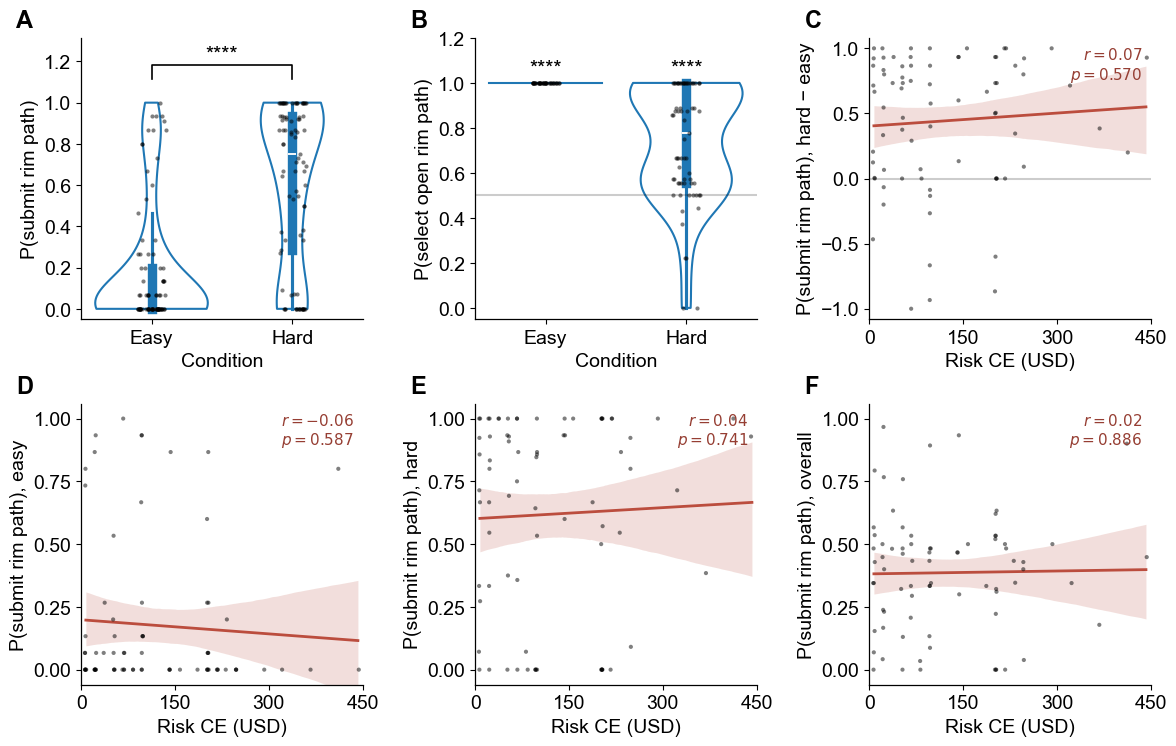

Saved: fig/exp1_survey/FigS6.pdf and fig/exp1_survey/FigS6.png


In [15]:
# Supplementary Figure S6

OUT_DIR = Path(globals().get('FIGURE_DIR', globals().get('figpath', '.')))
OUT_DIR.mkdir(parents=True, exist_ok=True)
BOOTSTRAP_N = 3000
PLOT_SEED = 0
SHOW_PEARSON_STATS = True
DOT_COLOR, DOT_ALPHA, DOT_SIZE = 'k', 0.5, 3
LINE_COLOR, STAT_COLOR = '#BB4D3E', '#963E33'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 14,
    'axes.linewidth': 0.9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})
rng = np.random.default_rng(PLOT_SEED)
trials = df_allsubjs_test.copy()

# ---- A: preserve original participant-by-condition aggregation ----
df_A = trials.groupby(['Subj', 'cond'], as_index=False)[['path_on_rim']].mean()

# ---- B: preserve original trial filters, aggregation, and annotations ----
df_temp = trials.copy()
df_temp = df_temp[df_temp['path_on_rim'] == 1]
df_temp = df_temp[df_temp['left_rim_path_open'] != df_temp['right_rim_path_open']]
df_temp = df_temp[~np.isnan(df_temp['path_taken_on_leftorrightrim'])]
df_temp['sensitive_to_whichrimopen'] = (
    df_temp['right_rim_path_open'] == df_temp['path_taken_on_leftorrightrim']
).astype(int)
df_temp_avg = df_temp.groupby(['Subj', 'cond'], as_index=False)[[
    'Subj', 'first_cond', 'trajectory_length', 'hit_wall', 'reached_goal',
    'submitted_in_time', 'trial_success', 'trial_bonus', 'path_on_rim',
    'full_path_on_rim', 'rimpath_agreement', 'rt', 'first_rt',
    'submitted_path_rt', 'submitted_path_presses', 'submitted_path_avgrt',
    'right_rim_path_open', 'path_taken_on_leftorrightrim',
    'sensitive_to_whichrimopen'
]].mean()

print('Panel B -- original one-sample tests:')
for cond_value, cond_name in [(0, 'Easy'), (1, 'Hard')]:
    vals = df_temp_avg.loc[
        df_temp_avg['cond'] == cond_value, 'sensitive_to_whichrimopen'
    ].dropna().to_numpy(float)
    if len(vals) >= 2:
        test = stats.ttest_1samp(vals, popmean=0.5)
        print(f'  {cond_name}: N={len(vals)}, mean={vals.mean():.6f}, '
              f't({len(vals)-1})={test.statistic:.4f}, p={test.pvalue:.4g}')
    else:
        print(f'  {cond_name}: N={len(vals)} -- insufficient data')

# ---- C-F: extract risk data exclusively from df_allsubjs_test ----
risk_columns = ['risk_ce_midpoint', 'r_risk_ce_cohort_eligible']
missing = [c for c in risk_columns if c not in trials.columns]
if missing:
    raise KeyError(
        f'Cannot draw panels C-F: df_allsubjs_test lacks {missing}. '
        'The CE and risk-cohort eligibility must be present in this DataFrame; '
        'they cannot be inferred from maze outcomes alone.'
    )

# A participant must not have conflicting CE or eligibility values across trials.
for col in risk_columns:
    if (trials.groupby('Subj')[col].nunique(dropna=True) > 1).any():
        raise ValueError(f'Conflicting within-participant values in {col!r}.')

risk_by_subj = trials.groupby('Subj')[risk_columns].first()
risk_by_subj['risk_ce_midpoint'] = pd.to_numeric(
    risk_by_subj['risk_ce_midpoint'], errors='coerce'
)
risk_eligible = (
    risk_by_subj['r_risk_ce_cohort_eligible']
    .astype('string').str.strip().str.lower()
    .isin(['true', '1', '1.0'])
)

rim_by_cond = (
    trials.groupby(['Subj', 'cond'])['path_on_rim'].mean()
    .unstack('cond').reindex(columns=[0, 1])
    .rename(columns={0: 'rim_easy', 1: 'rim_hard'})
)
rim_overall = trials.groupby('Subj')['path_on_rim'].mean().rename('rim_overall')
ce_rim = (
    risk_by_subj.loc[risk_eligible, ['risk_ce_midpoint']]
    .join(rim_by_cond, how='inner')
    .join(rim_overall, how='inner')
    .dropna(subset=['risk_ce_midpoint', 'rim_easy', 'rim_hard', 'rim_overall'])
    .copy()
)
ce_rim['rim_delta'] = ce_rim['rim_hard'] - ce_rim['rim_easy']
print(f"Panel A: {df_A['Subj'].nunique()} participants; "
      f'Panels C-F: {len(ce_rim)} eligible participants')
if len(ce_rim) != 76:
    print('NOTE: Risk sample size differs from the reported N=76.')


def label_panel(ax, letter):
    ax.text(-0.23, 1.02, letter, transform=ax.transAxes,
            ha='left', va='bottom', fontsize=17, fontweight='bold',
            fontfamily='Arial', clip_on=False)


def style_axes(ax):
    sns.despine(ax=ax)
    ax.tick_params(axis='both', length=3.5, width=0.8)
    ax.grid(False)


def draw_scatter_fit(ax, x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    # Same point style as the violin stripplots; jitter is visual only.
    ax.scatter(x + rng.uniform(-1.5, 1.5, len(x)), y,
               s=DOT_SIZE**2, color=DOT_COLOR, alpha=DOT_ALPHA,
               linewidths=0, edgecolors='none', zorder=3)

    if len(x) >= 3 and np.unique(x).size > 1 and np.unique(y).size > 1:
        fit = stats.linregress(x, y)
        xx = np.linspace(x.min(), x.max(), 160)
        yy = fit.intercept + fit.slope * xx
        inds = rng.integers(0, len(x), size=(BOOTSTRAP_N, len(x)))
        xb, yb = x[inds], y[inds]
        xm, ym = xb.mean(axis=1), yb.mean(axis=1)
        xbc = xb - xm[:, None]
        denom = np.sum(xbc**2, axis=1)
        good = denom > 0
        if np.any(good):
            slopes = (
                np.sum(xbc[good] * (yb[good] - ym[good, None]), axis=1)
                / denom[good]
            )
            intercepts = ym[good] - slopes * xm[good]
            predictions = intercepts[:, None] + slopes[:, None] * xx[None, :]
            lower, upper = np.percentile(predictions, [2.5, 97.5], axis=0)
            ax.fill_between(xx, lower, upper, color=LINE_COLOR,
                            alpha=0.18, linewidth=0, zorder=1)
        ax.plot(xx, yy, color=LINE_COLOR, linewidth=2, zorder=2)
        if SHOW_PEARSON_STATS:
            r, p = stats.pearsonr(x, y)
            ax.text(0.97, 0.97, rf'$r={r:.2f}$' + '\n' + rf'$p={p:.3f}$',
                    transform=ax.transAxes, ha='right', va='top',
                    fontsize=11, color=STAT_COLOR)

    ax.set_xlabel('Risk CE (USD)')
    ax.set_xlim(0, 450)
    ax.set_xticks([0, 150, 300, 450])
    style_axes(ax)


fig, axes = plt.subplots(2, 3, figsize=(13.8, 8.4))
A, B, C, D, E, F = axes.flat

# ---- A: original plotting and paired significance ----
sns.violinplot(data=df_A, x='cond', y='path_on_rim',
               cut=0, inner='box', fill=False, ax=A)
sns.stripplot(data=df_A, x='cond', y='path_on_rim', dodge=True,
              color='k', alpha=0.5, size=3, legend=False, ax=A)
annotate_paired(ax=A, df=df_A, x='cond', y='path_on_rim', hue=None,
                pairs=[(0, 1)], order=[0, 1], text_offset=0.06)
A.set_xlim([-0.5, 1.5])
A.set_ylabel('P(submit rim path)')
A.set_xlabel('Condition')
A.set_xticks([0, 1], ['Easy', 'Hard'])
style_axes(A)

# ---- B: original plotting and one-sample significance ----
sns.violinplot(data=df_temp_avg, x='cond', y='sensitive_to_whichrimopen',
               cut=0, inner='box', fill=False, ax=B)
sns.stripplot(data=df_temp_avg, x='cond', y='sensitive_to_whichrimopen',
              dodge=True, color='k', alpha=0.5, size=3, legend=False, ax=B)
annotate_violin_significance(
    ax=B, df=df_temp_avg, x='cond', y='sensitive_to_whichrimopen',
    hue=None, test='t', mu=0.5, y_offset=0.02, min_height_pad=-0.1
)
B.plot([-1, 2], [0.5, 0.5], 'k-', alpha=0.2)
B.set_xlim([-0.5, 1.5])
B.set_ylim([None, 1.2])
B.set_ylabel('P(select open rim path)')
B.set_xlabel('Condition')
B.set_xticks([0, 1], ['Easy', 'Hard'])
style_axes(B)

# ---- C-F: CE scatterplots ----
x = ce_rim['risk_ce_midpoint'].to_numpy(float)
for ax, outcome, ylabel in [
    (C, 'rim_delta', 'P(submit rim path), hard − easy'),
    (D, 'rim_easy', 'P(submit rim path), easy'),
    (E, 'rim_hard', 'P(submit rim path), hard'),
    (F, 'rim_overall', 'P(submit rim path), overall'),
]:
    y = ce_rim[outcome].to_numpy(float)
    draw_scatter_fit(ax, x, y)
    ax.set_ylabel(ylabel)
    if outcome == 'rim_delta':
        ax.axhline(0, color='k', linestyle='-', alpha=0.2)
        ax.set_ylim(min(y.min(), 0) - 0.08, max(y.max(), 0) + 0.08)
    else:
        ax.set_ylim(-0.06, 1.06)
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])

for ax, letter in zip(axes.flat, 'ABCDEF'):
    label_panel(ax, letter)

fig.subplots_adjust(wspace=0.4, hspace=0.3)
pdf_path, png_path = OUT_DIR / 'FigS6.pdf', OUT_DIR / 'FigS6.png'
fig.savefig(pdf_path, bbox_inches='tight')
fig.savefig(png_path, dpi=350, bbox_inches='tight')
plt.show()
print(f'Saved: {pdf_path} and {png_path}')


## Detailed results

 comparison  n  df      t     p  cohen_dz
cond 0 vs 1 85  84 -7.784 0.000    -0.844
 comparison  n  df      t     p  cohen_dz
cond 0 vs 1 85  84 -6.502 0.000    -0.705


/var/folders/l2/2b4674qs2fd30bck37lz12740000gp/T/ipykernel_240/1478487157.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels(["Easy","Hard"])
/var/folders/l2/2b4674qs2fd30bck37lz12740000gp/T/ipykernel_240/1478487157.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(["Easy","Hard"])
/Users/liu_s/pyro_env2/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/var/folders/l2/2b4674qs2fd30bck37lz12740000gp/T/ipykernel_240/1478487157.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a Fi

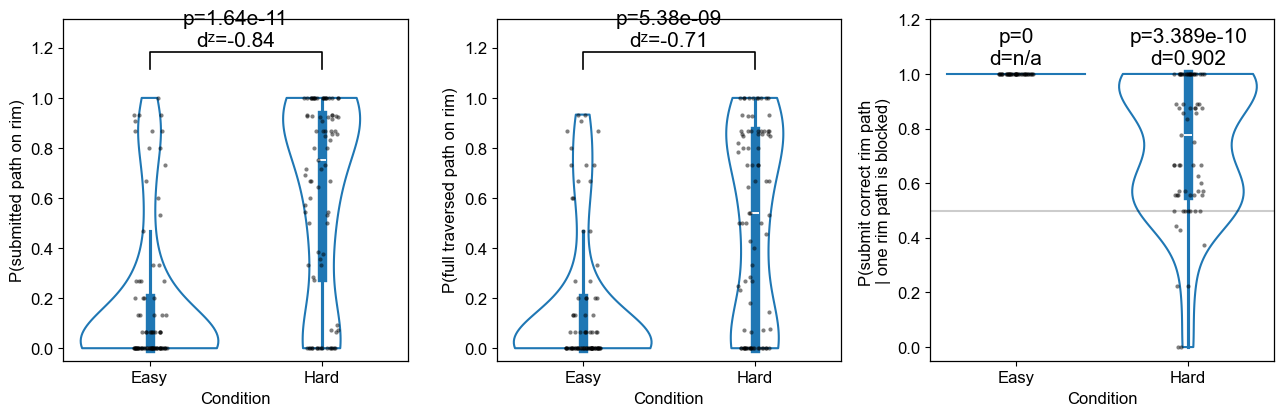

In [16]:
if RUN_ORIGINAL_ANALYSES and n_subj >= 2:
    # Set the default font family to sans-serif
    plt.rcParams['font.family'] = 'sans-serif'
    # Specify Arial as the preferred sans-serif font
    plt.rcParams['font.sans-serif'] = ['Arial']
    # Set the default font size to 12
    plt.rcParams['font.size'] = 12
    cut=0

    df_allsubjs_test_avg = df_allsubjs_test.groupby(['Subj','cond'], as_index=False)[["cond","first_cond","trajectory_length",
           "hit_wall", "reached_goal", "submitted_in_time", "trial_success",
           "trial_bonus","path_on_rim","full_path_on_rim", "rimpath_agreement", "rt", "first_rt", "submitted_path_avgrt"]].mean()
    x_order = [0,1]

    # Prepare figure
    fig, ax = plt.subplots(1, 3, figsize=(13, 13/3))

    # Shared orders

    # Row 2
    sns.violinplot(data=df_allsubjs_test_avg, x="cond", y="path_on_rim", cut=cut, fill=False, ax=ax[0])
    sns.stripplot(data=df_allsubjs_test_avg, x="cond", y="path_on_rim", dodge=True,
                  color="k", alpha=0.5, size=3, legend=False, ax=ax[0])
    # annotate: no hue
    annotate_paired(
        ax=ax[0], df=df_allsubjs_test_avg,
        x="cond", y="path_on_rim", hue=None,
        pairs=[(0, 1)],
        order=x_order,
        text_offset=0.06,
        label='p_and_d',       # 'stars' | 'p' | 'p_and_d'
    )
    ax[0].set_xlim([-0.5,1.5])
    ax[0].set_ylabel("P(submitted path on rim)")
    ax[0].set_xlabel("Condition")
    ax[0].set_xticklabels(["Easy","Hard"])

    # Row 2
    sns.violinplot(data=df_allsubjs_test_avg, x="cond", y="full_path_on_rim", cut=cut, fill=False, ax=ax[1])
    sns.stripplot(data=df_allsubjs_test_avg, x="cond", y="full_path_on_rim", dodge=True,
                  color="k", alpha=0.5, size=3, legend=False, ax=ax[1])
    # annotate: no hue
    annotate_paired(
        ax=ax[1], df=df_allsubjs_test_avg,
        x="cond", y="full_path_on_rim", hue=None,
        pairs=[(0, 1)],
        order=x_order,
        text_offset=0.06,
        label='p_and_d',       # 'stars' | 'p' | 'p_and_d'
    )
    ax[1].set_xlim([-0.5,1.5])
    ax[1].set_ylabel("P(full traversed path on rim)")
    ax[1].set_xlabel("Condition")
    ax[1].set_xticklabels(["Easy","Hard"])


    # Row 3
    df_temp = df_allsubjs_test.copy()

    df_temp = df_temp[df_temp["path_on_rim"]==1] # Trials where participant used rim paths
    df_temp = df_temp[df_temp["left_rim_path_open"] != df_temp["right_rim_path_open"]] # Trials where only one out of the two rim paths is open
    df_temp = df_temp[~np.isnan(df_temp["path_taken_on_leftorrightrim"])]
    df_temp["sensitive_to_whichrimopen"] = (df_temp["right_rim_path_open"]==df_temp["path_taken_on_leftorrightrim"]).astype(int) # For the above trials, did the subjects submit the (unique) open rim path? 
    # Take mean over subjects
    df_temp_avg = df_temp.groupby(['Subj',"cond"], as_index=False)[["Subj","first_cond","trajectory_length",
           "hit_wall", "reached_goal", "submitted_in_time", "trial_success",
           "trial_bonus","path_on_rim","full_path_on_rim", "rimpath_agreement", "rt", "first_rt", "submitted_path_rt", "submitted_path_presses", "submitted_path_avgrt","right_rim_path_open","path_taken_on_leftorrightrim","sensitive_to_whichrimopen"]].mean()
    sns.violinplot(data=df_temp_avg, x="cond",y="sensitive_to_whichrimopen", cut=cut, fill=False, ax=ax[2])
    sns.stripplot(data=df_temp_avg, x="cond",y="sensitive_to_whichrimopen", dodge=True,
                  color="k", alpha=0.5, size=3, legend=False, ax=ax[2])
    annotate_violin_significance(
        ax=ax[2],
        df=df_temp_avg,
        x="cond",
        y="sensitive_to_whichrimopen",
        hue=None,
        test="t",            # "t" for one-sample t-test, "wilcoxon" for signed-rank
        mu=0.5,
        y_offset=0.02,
        min_height_pad=-0.1,
        show='p_and_d',       # 'stars' | 'p' | 'p_and_d' 
    )
    ax[2].plot([-1,2],[0.5,0.5],"k-",alpha=0.2)
    ax[2].set_xlim([-0.5,1.5])
    ax[2].set_ylim([None,1.2])
    #ax[2].set_yticks([-0,0.5,1])
    ax[2].set_ylabel("P(submit correct rim path \n| one rim path is blocked)")
    ax[2].set_xlabel("Condition")
    ax[2].set_xticklabels(["Easy","Hard"])


    # # Set titles
    # ax[0].set(title=f"All participants; N={n_subj}")

    fig.tight_layout()
    # plt.savefig(os.path.join(figpath, "exp1_results_pvals"), dpi=300)
    # plt.savefig(os.path.join(figpath, "exp1_results_pvals.pdf"), bbox_inches='tight')
    plt.show()
else:
    print('Skipped: insufficient included participants or optional section disabled.')


Risk-eligible participants: N=76


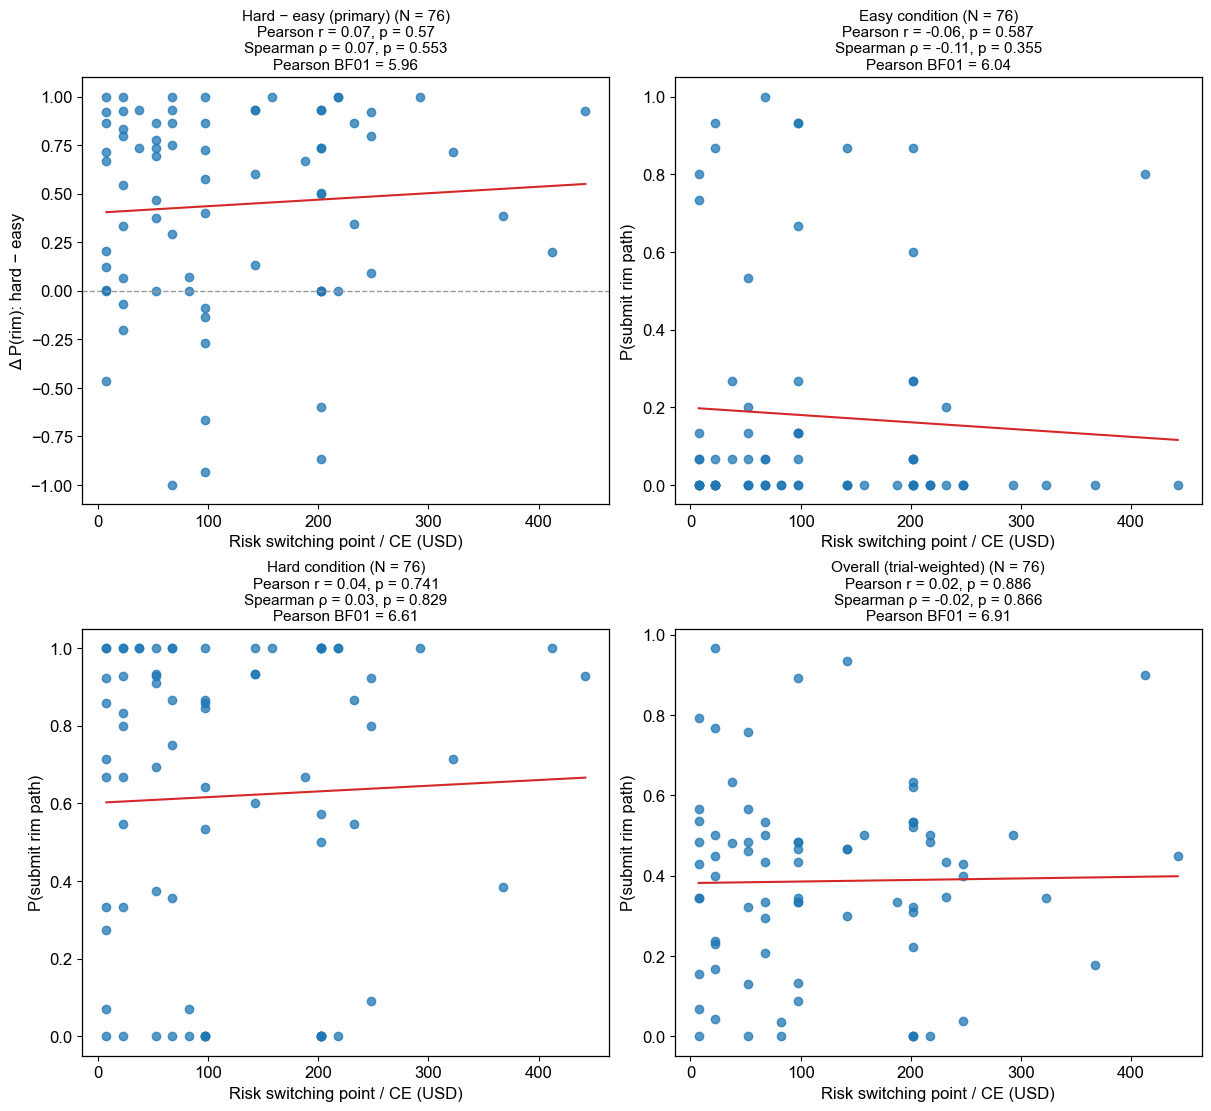

,outcome,N,Pearson_r,Pearson_p,Pearson_95CI_low,Pearson_95CI_high,Spearman_rho,Spearman_p,Pearson_BF10,Pearson_BF01,BF_method,BF_kappa
0,Hard − easy (primary),76,0.066137,0.570285,-0.161731,0.287308,0.069097,0.553113,0.167830,5.958397,ly,1.0
1,Easy condition,76,-0.063306,0.586929,-0.284698,0.164497,-0.107539,0.355148,0.165619,6.037961,ly,1.0
2,Hard condition,76,0.038566,0.740824,-0.188529,0.261746,0.025223,0.828772,0.151194,6.614039,ly,1.0
3,Overall (trial-weighted),76,0.016758,0.885752,-0.209489,0.241302,-0.019610,0.866472,0.144751,6.908394,ly,1.0


,outcome,N,slope_per_100_USD_CE,bootstrap_95CI_low,bootstrap_95CI_high
0,Hard − easy (primary),76,0.033392,-0.065818,0.126804
1,Easy condition,76,-0.018738,-0.089886,0.052375
2,Hard condition,76,0.014654,-0.070707,0.084582
3,Overall (trial-weighted),76,0.003841,-0.053926,0.059429


In [17]:
# Risk correlation analyses using ONLY df_allsubjs_test.
# Only participant identifier is the deidentified column Subj.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pingouin import bayesfactor_pearson

OUTPUT_DIR = Path(globals().get('OUTPUT_DIR', '.'))
FIGURE_DIR = Path(globals().get('FIGURE_DIR', globals().get('figpath', '.')))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RISK_BOOTSTRAP_SAMPLES = 5000
RISK_BOOTSTRAP_SEED = 0
BF_METHOD, BF_KAPPA = 'ly', 1.0

trials = df_allsubjs_test.copy()
required = ['Subj', 'cond', 'path_on_rim', 'full_path_on_rim',
            'risk_ce_midpoint', 'r_risk_ce_cohort_eligible']
missing = [c for c in required if c not in trials.columns]
if missing:
    raise KeyError(
        f'df_allsubjs_test lacks {missing}. Risk CE and eligibility cannot '
        'be reconstructed from maze-trial outcomes alone.'
    )

risk_cols = ['risk_ce_midpoint', 'r_risk_ce_cohort_eligible']
for col in risk_cols:
    if (trials.groupby('Subj')[col].nunique(dropna=True) > 1).any():
        raise ValueError(f'Conflicting within-participant values in {col!r}.')
risk_by_subj = trials.groupby('Subj')[risk_cols].first()
risk_by_subj['risk_ce_midpoint'] = pd.to_numeric(
    risk_by_subj['risk_ce_midpoint'], errors='coerce'
)
eligible = (
    risk_by_subj['r_risk_ce_cohort_eligible']
    .astype('string').str.strip().str.lower()
    .isin(['true', '1', '1.0'])
)

rim_probs = (
    trials.groupby(['Subj', 'cond'])['path_on_rim'].mean()
    .unstack('cond').reindex(columns=[0, 1])
    .rename(columns={0: 'rim_easy', 1: 'rim_hard'})
)
overall = trials.groupby('Subj')['path_on_rim'].mean().rename('rim_overall')
ce_rim = (
    risk_by_subj.loc[eligible, ['risk_ce_midpoint']]
    .join(rim_probs, how='inner')
    .join(overall, how='inner')
    .dropna(subset=['risk_ce_midpoint', 'rim_easy', 'rim_hard', 'rim_overall'])
    .copy()
)
ce_rim['rim_delta'] = ce_rim['rim_hard'] - ce_rim['rim_easy']
ce_rim.to_csv(OUTPUT_DIR / 'subject_rim_delta_covariates.csv', index_label='Subj')

columns = ['rim_delta', 'rim_easy', 'rim_hard', 'rim_overall']
labels = ['Hard − easy (primary)', 'Easy condition', 'Hard condition',
          'Overall (trial-weighted)']
correlation_rows, slope_rows = [], []
n = len(ce_rim)
print(f'Risk-eligible participants: N={n}')

if n == 0:
    print('Risk correlations unavailable: no eligible participants with both conditions.')
else:
    x = ce_rim['risk_ce_midpoint'].to_numpy(float)
    Y = ce_rim[columns].to_numpy(float)
    fig, axes = plt.subplots(2, 2, figsize=(12, 11), constrained_layout=True)
    estimates = np.full(4, np.nan)
    boot_slopes = np.full((RISK_BOOTSTRAP_SAMPLES, 4), np.nan)

    if n >= 3 and np.unique(x).size > 1:
        xc = x - x.mean()
        estimates = (xc @ (Y - Y.mean(axis=0)) / np.sum(xc**2)) * 100
        rng = np.random.default_rng(RISK_BOOTSTRAP_SEED)
        for b in range(RISK_BOOTSTRAP_SAMPLES):
            idx = rng.integers(0, n, size=n)
            xb, yb = x[idx], Y[idx]
            xbc = xb - xb.mean()
            denominator = np.sum(xbc**2)
            if denominator > 0:
                boot_slopes[b] = (
                    xbc @ (yb - yb.mean(axis=0)) / denominator
                ) * 100

    for j, (ax, label) in enumerate(zip(axes.flat, labels)):
        y = Y[:, j]
        ax.scatter(x, y, alpha=.75)
        ax.set(
            xlabel='Risk switching point / CE (USD)',
            ylabel='Δ P(rim): hard − easy' if j == 0 else 'P(submit rim path)'
        )
        p_r = p_p = s_r = s_p = ci_low = ci_high = np.nan
        bf10 = bf01 = np.nan
        valid = (
            n >= 3 and np.isfinite(x).all() and np.isfinite(y).all()
            and np.unique(x).size > 1 and np.unique(y).size > 1
        )
        if valid:
            pearson = stats.pearsonr(x, y)
            spearman = stats.spearmanr(x, y)
            p_r, p_p = pearson.statistic, pearson.pvalue
            s_r, s_p = spearman.statistic, spearman.pvalue
            if n > 3 and abs(p_r) < 1:
                z = np.arctanh(p_r)
                ci_low, ci_high = np.tanh(
                    z + np.array([-1, 1]) * stats.norm.ppf(.975) / np.sqrt(n - 3)
                )
            if n >= 4:
                bf10 = float(bayesfactor_pearson(
                    r=float(p_r), n=n, alternative='two-sided',
                    method=BF_METHOD, kappa=BF_KAPPA
                ))
                if bf10 > 0:
                    bf01 = 1.0 / bf10
                elif bf10 == 0:
                    bf01 = np.inf
            fit = stats.linregress(x, y)
            xx = np.linspace(x.min(), x.max(), 100)
            ax.plot(xx, fit.intercept + fit.slope * xx, color='tab:red')
            bf_text = f'{bf01:.3g}' if not np.isnan(bf01) else 'undefined'
            subtitle = (
                f'Pearson r = {p_r:.2f}, p = {p_p:.3g}\n'
                f'Spearman ρ = {s_r:.2f}, p = {s_p:.3g}\n'
                f'Pearson BF01 = {bf_text}'
            )
        else:
            subtitle = 'Correlations undefined: insufficient or constant data'
        ax.set_title(f'{label} (N = {n})\n{subtitle}', fontsize=11)
        if j == 0:
            ax.axhline(0, color='0.6', ls='--', lw=1)
        correlation_rows.append(dict(
            outcome=label, N=n,
            Pearson_r=p_r, Pearson_p=p_p,
            Pearson_95CI_low=ci_low, Pearson_95CI_high=ci_high,
            Spearman_rho=s_r, Spearman_p=s_p,
            Pearson_BF10=bf10, Pearson_BF01=bf01,
            BF_method=BF_METHOD, BF_kappa=BF_KAPPA
        ))
        finite = boot_slopes[:, j][np.isfinite(boot_slopes[:, j])]
        lo, hi = (np.percentile(finite, [2.5, 97.5])
                  if len(finite) else (np.nan, np.nan))
        slope_rows.append(dict(
            outcome=label, N=n, slope_per_100_USD_CE=estimates[j],
            bootstrap_95CI_low=lo, bootstrap_95CI_high=hi
        ))

    fig.savefig(FIGURE_DIR / 'rim_risk_correlations.pdf', bbox_inches='tight')
    plt.show()
    if np.isfinite(estimates).all():
        assert np.isclose(estimates[0], estimates[2] - estimates[1])

correlation_results = pd.DataFrame(correlation_rows, columns=[
    'outcome', 'N', 'Pearson_r', 'Pearson_p', 'Pearson_95CI_low',
    'Pearson_95CI_high', 'Spearman_rho', 'Spearman_p',
    'Pearson_BF10', 'Pearson_BF01', 'BF_method', 'BF_kappa'
])
slope_summary = pd.DataFrame(slope_rows, columns=[
    'outcome', 'N', 'slope_per_100_USD_CE',
    'bootstrap_95CI_low', 'bootstrap_95CI_high'
])
correlation_results.to_csv(OUTPUT_DIR / 'risk_rim_correlations.csv', index=False)
slope_summary.to_csv(OUTPUT_DIR / 'risk_rim_slopes.csv', index=False)
try:
    display(correlation_results)
    display(slope_summary)
except NameError:
    print(correlation_results.to_string(index=False))
    print(slope_summary.to_string(index=False))


# Sanity check figures

In [18]:
def annotate_paired(
    ax, df, x, y, hue=None, pairs=None,
    order=None, hue_order=None,
    cat_width=0.8,       # match seaborn's violinplot width
    text_offset=0.06,    # fraction of y-range between brackets
    linewidth=1.2, fontsize=15,
    label='stars',       # 'stars' | 'p' | 'p_and_d'
    test_type = "paired-t", # "paired-t" | "wilcoxon"
    print_table=True,    # print a table of results
    return_table=False,  # return the results DataFrame
    decimals=3           # rounding in printed table
):
    """
    Draw paired t-test brackets and (optionally) print/return stats.
    If hue is None: pairs = [(x1, x2), ...]
    If hue is not None: pairs = [((x1,h1),(x2,h2)), ...]

    Effect size reported: Cohen's dz = mean(diff)/sd(diff), paired design.
    """
    # Ensure Subject column for pairing
    if 'Subj' not in df.columns:
        df = df.reset_index()

    # Resolve plotting orders
    if order is None:
        order = list(pd.unique(df[x]))
    if hue is not None and hue_order is None:
        hue_order = list(pd.unique(df[hue]))

    # ---- centers that match split-violins exactly ----
    if hue is None:
        offset_map = {None: 0.0}
    else:
        k = len(hue_order)
        cell = cat_width / float(k)  # width per split violin
        centers = np.linspace(-cat_width/2 + cell/2,
                              +cat_width/2 - cell/2, k)
        offset_map = {h: centers[i] for i, h in enumerate(hue_order)}

    def xpos(x_level, h_level=None):
        xi = order.index(x_level)
        return xi + (offset_map[None] if hue is None else offset_map[h_level])

    # ---- compute stats for each pair ----
    rows = []
    for pr in pairs:
        if hue is None:
            x1, x2 = pr
            d1 = df[df[x] == x1][['Subj', y]].rename(columns={y:'v1'})
            d2 = df[df[x] == x2][['Subj', y]].rename(columns={y:'v2'})
            lab = f"{x} {x1} vs {x2}"
        else:
            (x1, h1), (x2, h2) = pr
            d1 = df[(df[x] == x1) & (df[hue] == h1)][['Subj', y]].rename(columns={y:'v1'})
            d2 = df[(df[x] == x2) & (df[hue] == h2)][['Subj', y]].rename(columns={y:'v2'})
            lab = f"({x1},{h1}) vs ({x2},{h2})"

        merged = pd.merge(d1, d2, on='Subj').dropna(subset=['v1','v2'])
        n = len(merged)
        if n >= 2:
            diff = (merged['v1'] - merged['v2']).to_numpy(dtype=float)
            sd = np.std(diff, ddof=1)
            dz = np.nan if sd == 0 else np.mean(diff) / sd
            if(test_type=="paired-t"):
                t_stat, p = ttest_rel(merged['v1'], merged['v2'])
            elif(test_type=="wilcoxon"):
                t_stat, p = wilcoxon(merged['v1'], merged['v2'])
            dfree = n - 1
        else:
            t_stat = p = dz = np.nan
            dfree = n - 1

        rows.append({
            'comparison': lab, 'n': n, 'df': dfree,
            't': t_stat, 'p': p, 'cohen_dz': dz
        })

    results = pd.DataFrame(rows)

    # ---- vertical layout & draw ----
    ymin, ymax = ax.get_ylim()
    yr = max(ymax - ymin, 1e-9)
    step = text_offset * yr
    ax.set_ylim(ymin, ymax + step * (len(pairs)*3 + 1))

    for i, pr in enumerate(pairs):
        if hue is None:
            x1, x2 = pr
            x1p, x2p = xpos(x1), xpos(x2)
        else:
            (x1, h1), (x2, h2) = pr
            x1p, x2p = xpos(x1, h1), xpos(x2, h2)

        stats = results.iloc[i]
        p = stats['p']; dz = stats['cohen_dz']

        # label text
        if label == 'stars':
            if   np.isnan(p): s = 'n/a'
            elif p < 1e-4:    s = '****'
            elif p < 1e-3:    s = '***'
            elif p < 1e-2:    s = '**'
            elif p < 5e-2:    s = '*'
            else:             s = 'n.s.'
        elif label == 'p':
            s = f"p={p:.3g}" if not np.isnan(p) else "p=n/a"
        elif label == 'p_and_d':
            sp = f"p={p:.3g}" if not np.isnan(p) else "p=n/a"
            sd = f"dᶻ={dz:.2f}" if not np.isnan(dz) else "dᶻ=n/a"
            s = sp + "\n" + sd
        else:
            s = ''

        # bracket height for this pair
        yb = ymax + step * (i*3 + 1)
        ytop = yb + step

        ax.plot([x1p, x1p, x2p, x2p], [yb, ytop, ytop, yb],
                'k-', lw=linewidth, clip_on=False)
        ax.text((x1p+x2p)/2.0, ytop + 0.12*step, s,
                ha='center', va='bottom', fontsize=fontsize, clip_on=False)

    # ---- print & return ----
    if print_table:
        with pd.option_context('display.float_format', lambda v: f"{v:.{decimals}f}"):
            print(results.to_string(index=False))

    if return_table:
        return results

        


 comparison  n  df      t     p  cohen_dz
cond 0 vs 1 85  84 11.726 0.000     1.272
 comparison  n  df      t     p  cohen_dz
cond 0 vs 1 85  84 -7.784 0.000    -0.844
 comparison  n  df      t     p  cohen_dz
cond 0 vs 1 85  84 -6.502 0.000    -0.705
 comparison  n  df      t     p  cohen_dz
cond 0 vs 1 85  84 -9.850 0.000    -1.068
 comparison  n  df      t     p  cohen_dz
cond 0 vs 1 85  84 -5.204 0.000    -0.564
        comparison  n  df     t     p  cohen_dz
(0,0.0) vs (1,0.0) 41  40 7.624 0.000     1.191
(0,1.0) vs (1,1.0) 44  43 8.883 0.000     1.339
        comparison  n  df      t     p  cohen_dz
(0,0.0) vs (1,0.0) 41  40 -4.541 0.000    -0.709
(0,1.0) vs (1,1.0) 44  43 -6.807 0.000    -1.026
        comparison  n  df      t     p  cohen_dz
(0,0.0) vs (1,0.0) 41  40 -4.553 0.000    -0.711
(0,1.0) vs (1,1.0) 44  43 -4.736 0.000    -0.714
        comparison  n  df      t     p  cohen_dz
(0,0.0) vs (1,0.0) 41  40 -5.008 0.000    -0.782
(0,1.0) vs (1,1.0) 44  43 -9.528 0.000    -1

/var/folders/l2/2b4674qs2fd30bck37lz12740000gp/T/ipykernel_240/3831408393.py:82: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  g=sns.stripplot(
/var/folders/l2/2b4674qs2fd30bck37lz12740000gp/T/ipykernel_240/3831408393.py:92: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  g=sns.stripplot(
/var/folders/l2/2b4674qs2fd30bck37lz12740000gp/T/ipykernel_240/3831408393.py:102: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  g=sns.stripplot(
/var/folders/l2/2b4674qs2fd30bck37lz12740000gp/T/ipykernel_240/3831408393.py:112: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  g=sns.stripplot(
/var/f

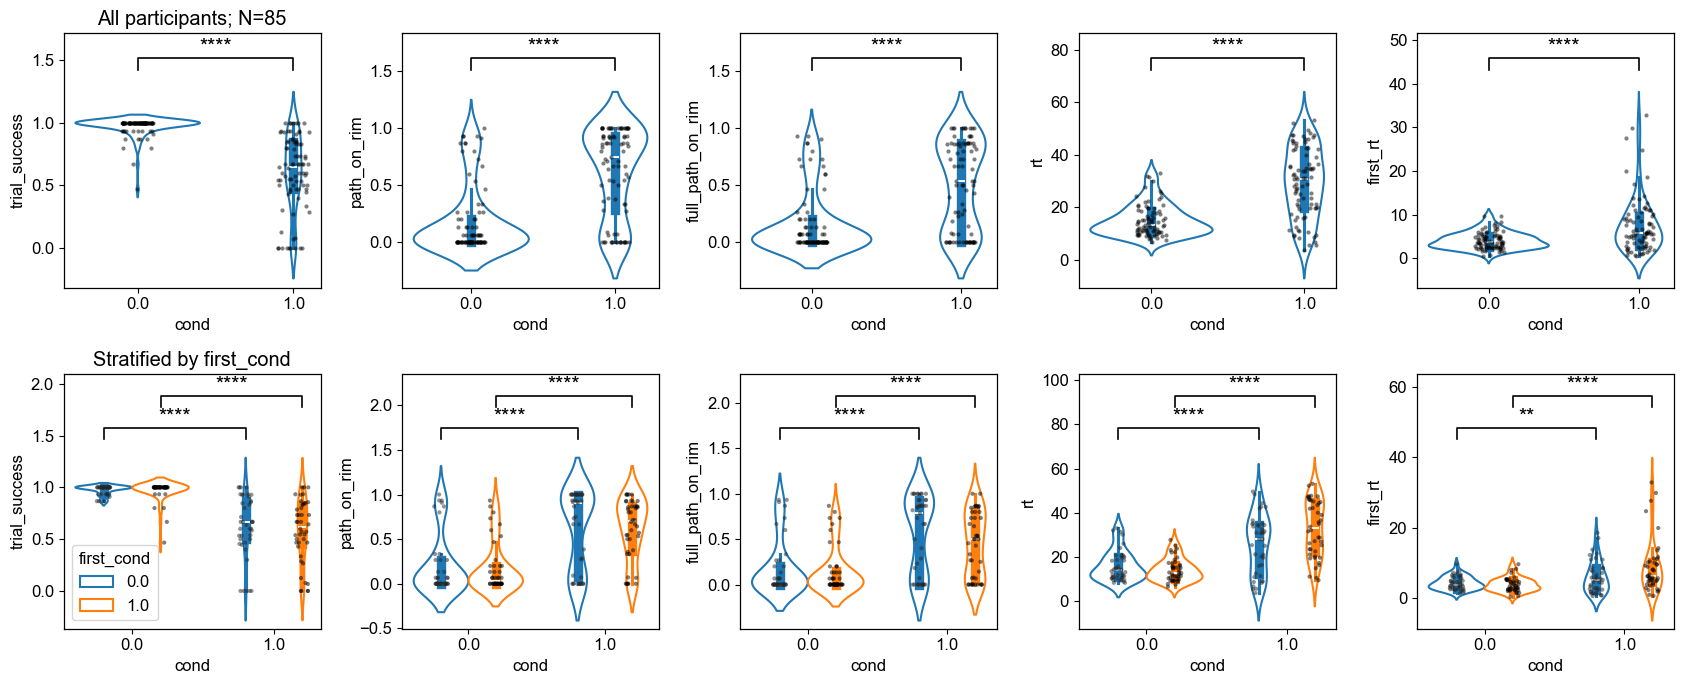

In [19]:
if RUN_ORIGINAL_ANALYSES and n_subj >= 2:
    df_allsubjs_test_avg = df_allsubjs_test.groupby(['Subj','num_colors'], as_index=False)[["cond","first_cond","trajectory_length",
           "hit_wall", "reached_goal", "submitted_in_time", "trial_success",
           "trial_bonus","path_on_rim","full_path_on_rim", "rimpath_agreement", "rt", "first_rt", "submitted_path_avgrt"]].mean()

    x_order = [0,1]

    # Prepare figure
    fig, ax = plt.subplots(2, 5, figsize=(17, 7))

    # Shared orders
    # Row 1
    sns.violinplot(data=df_allsubjs_test_avg, x="cond", y="trial_success", fill=False, ax=ax[0,0])
    sns.stripplot(data=df_allsubjs_test_avg, x="cond", y="trial_success", dodge=True,
                  color="k", alpha=0.5, size=3, legend=False, ax=ax[0,0])
    # annotate: no hue
    annotate_paired(
        ax=ax[0,0], df=df_allsubjs_test_avg,
        x="cond", y="trial_success", hue=None,
        pairs=[(0, 1)],
        order=x_order,
        text_offset=0.06
    )

    # Row 2
    sns.violinplot(data=df_allsubjs_test_avg, x="cond", y="path_on_rim", fill=False, ax=ax[0,1])
    sns.stripplot(data=df_allsubjs_test_avg, x="cond", y="path_on_rim", dodge=True,
                  color="k", alpha=0.5, size=3, legend=False, ax=ax[0,1])
    # annotate: no hue
    annotate_paired(
        ax=ax[0,1], df=df_allsubjs_test_avg,
        x="cond", y="path_on_rim", hue=None,
        pairs=[(0, 1)],
        order=x_order,
        text_offset=0.06
    )

    # Row 3
    sns.violinplot(data=df_allsubjs_test_avg, x="cond", y="full_path_on_rim", fill=False, ax=ax[0,2])
    sns.stripplot(data=df_allsubjs_test_avg, x="cond", y="full_path_on_rim", dodge=True,
                  color="k", alpha=0.5, size=3, legend=False, ax=ax[0,2])

    # annotate: no hue
    annotate_paired(
        ax=ax[0,2], df=df_allsubjs_test_avg,
        x="cond", y="full_path_on_rim", hue=None,
        pairs=[(0, 1)],
        order=x_order
    )

    # Row 4
    sns.violinplot(data=df_allsubjs_test_avg, x="cond", y="rt", fill=False, ax=ax[0,3])
    sns.stripplot(data=df_allsubjs_test_avg, x="cond", y="rt", dodge=True,
                  color="k", alpha=0.5, size=3, legend=False, ax=ax[0,3])

    # annotate: no hue
    annotate_paired(
        ax=ax[0,3], df=df_allsubjs_test_avg,
        x="cond", y="rt", hue=None,
        pairs=[(0, 1)],
        order=x_order
    )

    # Row 5
    sns.violinplot(data=df_allsubjs_test_avg, x="cond", y="first_rt", fill=False, ax=ax[0,4])
    sns.stripplot(data=df_allsubjs_test_avg, x="cond", y="first_rt", dodge=True,
                  color="k", alpha=0.5, size=3, legend=False, ax=ax[0,4])

    # annotate: no hue
    annotate_paired(
        ax=ax[0,4], df=df_allsubjs_test_avg,
        x="cond", y="first_rt", hue=None,
        pairs=[(0, 1)],
        order=x_order
    )

    # ===== Row 2: with hue = first_cond =====
    g=sns.violinplot(
        data=df_allsubjs_test_avg,
        x="cond", y="trial_success", hue="first_cond", fill=False, ax=ax[1,0]
    )
    g=sns.stripplot(
        data=df_allsubjs_test_avg,
        x="cond", y="trial_success", hue="first_cond", dodge=True,
        color="k", alpha=0.5, size=3, legend=False, ax=ax[1,0]
    )
    # Row 2
    g=sns.violinplot(
        data=df_allsubjs_test_avg,
        x="cond", y="path_on_rim", hue="first_cond", fill=False, ax=ax[1,1], legend=False
    )
    g=sns.stripplot(
        data=df_allsubjs_test_avg,
        x="cond", y="path_on_rim", hue="first_cond", dodge=True,
        color="k", alpha=0.5, size=3, legend=False, ax=ax[1,1]
    )
    # Row 3
    g=sns.violinplot(
        data=df_allsubjs_test_avg,
        x="cond", y="full_path_on_rim", hue="first_cond", fill=False, ax=ax[1,2], legend=False
    )
    g=sns.stripplot(
        data=df_allsubjs_test_avg,
        x="cond", y="full_path_on_rim", hue="first_cond", dodge=True,
        color="k", alpha=0.5, size=3, legend=False, ax=ax[1,2]
    )
    # Row 4
    g=sns.violinplot(
        data=df_allsubjs_test_avg,
        x="cond", y="rt", hue="first_cond", fill=False, ax=ax[1,3], legend=False
    )
    g=sns.stripplot(
        data=df_allsubjs_test_avg,
        x="cond", y="rt", hue="first_cond", dodge=True,
        color="k", alpha=0.5, size=3, legend=False, ax=ax[1,3]
    )
    # Row 5
    g=sns.violinplot(
        data=df_allsubjs_test_avg,
        x="cond", y="first_rt", hue="first_cond", fill=False, ax=ax[1,4], legend=False
    )
    g=sns.stripplot(
        data=df_allsubjs_test_avg,
        x="cond", y="first_rt", hue="first_cond", dodge=True,
        color="k", alpha=0.5, size=3, legend=False, ax=ax[1,4]
    )

    x_order = [0, 1]
    h_order = sorted(df_allsubjs_test_avg['first_cond'].dropna().unique().tolist())

    def four_pairs(x_order, h_order):
    #     # (1) within each cond: compare hues// Can't do this because paired t-test is within-subject
    #     within_cond = [((x, h_order[0]), (x, h_order[1])) for x in x_order]
        # (2) within each hue: compare conds
        within_hue  = [((x_order[0], h), (x_order[1], h)) for h in h_order]
        # return within_cond + within_hue
        return within_hue

    # Example for path_on_rim on row 2
    pairs4 = four_pairs(x_order, h_order)

    for j, (yy, ax_here) in enumerate([
        ('trial_success',    ax[1,0]),
        ('path_on_rim',      ax[1,1]),
        ('full_path_on_rim', ax[1,2]),
        ('rt',               ax[1,3]),
        ('first_rt',               ax[1,4]),
    ]):
        annotate_paired(
            ax=ax_here, df=df_allsubjs_test_avg,
            x="cond", y=yy, hue="first_cond",
            pairs=pairs4,
            order=x_order, hue_order=h_order,
            cat_width=0.8,     
            text_offset=0.06    
        )
    
    
    # Set titles
    ax[0,0].set(title=f"All participants; N={n_subj}")
    ax[1,0].set(title=f"Stratified by first_cond")

    fig.tight_layout()
    #plt.savefig(os.path.join(figpath, "exp1_pairedt_exclusion"), dpi=300)
    plt.show()
else:
    print('Skipped: insufficient included participants or optional section disabled.')
